# MiniMax H3 Image-to-Video on Google Colab T4 — Safety-Aware Public Demo

A ComfyUI-based experimental workflow for running a quantized MiniMax H3 image-to-video pipeline on a constrained NVIDIA T4 GPU.

## What this notebook demonstrates

- A GGUF-based diffusion transformer loaded through ComfyUI custom nodes.
- Image-to-video conditioning using an uploaded opening frame.
- A Turbo LoRA/sampler configuration for reduced-step generation.
- Resolution profiles and a strict maximum output-edge setting.
- Dedicated Turbo adapter for reduced-step sampling; no optional behavior/anatomy LoRA catalogue.
- Prompt screening and sampled-frame output moderation for the public demo.
- Local generation with optional external conditioning, depending on the selected mode.

## Reproducibility notes

- Start with the Fast profile, a short clip, and the default output-edge cap.
- Run cells in order in a fresh Google Colab GPU runtime.
- Model files and generated videos are not included in this repository.
- The notebook was cleaned for public presentation; rerun it to create fresh outputs and verify current upstream compatibility.
- Safety checks are best-effort: keyword screening can be bypassed and frame sampling can miss brief content. Do not treat them as a guarantee.
- Runtime behavior depends on Colab GPU availability, upstream model files, ComfyUI/custom-node revisions, and external conditioning service availability.

This is an engineering workflow, not a claim that quantized output matches full-precision quality or that the configuration is universally optimal.


## 1. Model settings

Run the cells in order. This notebook uses the ComfyUI API backend and does not compile `stable-diffusion.cpp`.

The default conditioning backend is the **local ComfyUI text encoder**, so no Hugging Face ZeroGPU inference request is made. This text encoder is large and can still pressure Colab host RAM on long clips or when many LoRAs are enabled.

The resolution controls now offer **Fast / Medium / Full** tiers, automatic aspect-family selection, a strict `MAX_OUTPUT_LONG_EDGE` cap, and manual width/height. The default is **Fast + Auto ratio + a 640-pixel hard cap**. All local output dimensions are multiples of 32, and the preview cell verifies that a numeric cap is never exceeded.

For the most reliable T4 baseline, start with Fast profile, auto aspect ratio, a 640-pixel cap, Turbo, and a short clip. Only increase the cap or switch to Full after confirming the current configuration completes.

In [12]:
# @title 1. Model settings
# Store a Hugging Face token as a Colab Secret named HF_TOKEN and enable notebook access.
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = None

if HF_TOKEN:
    print("Hugging Face token loaded from Colab Secrets (used for model/LoRA downloads where needed).")
else:
    print("HF_TOKEN is missing. Public downloads can still work; private/gated models and LoRAs may need it.")

CONDITIONER_SPACE = "multimodalart/qwen3vl-conditioner"
REMOTE_CONDITIONING = "Remote Qwen3-VL conditioner (lower T4 memory; may hit Space quota)"
LOCAL_CONDITIONING = "Local ComfyUI text encoder (no ZeroGPU; experimental on T4)"
CONDITIONING_BACKEND = "Remote Qwen3-VL conditioner (lower T4 memory; may hit Space quota)" # @param ["Local ComfyUI text encoder (no ZeroGPU; experimental on T4)", "Remote Qwen3-VL conditioner (lower T4 memory; may hit Space quota)"]
# Only set True if you intentionally want the remote Space request authenticated as your HF user.
CONDITIONER_USE_PERSONAL_ZEROGPU_QUOTA = True # @param {type:"boolean"}
TEXT_ENCODER_REPO = "Comfy-Org/MiniMax-H3"
TEXT_ENCODER_FILE = "qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors"
TEXT_ENCODER_DIR = "/content/ComfyUI/models/text_encoders"

# Use the U16G format made for the matching molbal/ComfyUI-GGUF loader, rather than an unsupported/slow K-quant diffusion file.
DIFFUSION_PRESET = "Q4_0 standard 4-bit (lower memory fallback)" # @param ["U16G mixed INT8 + Q4_0 (recommended 16-GB-class balance)", "Q4_0 standard 4-bit (lower memory fallback)", "Q5_0 standard 5-bit (high-memory experiment; explicit opt-in required)"]
DIFFUSION_VARIANTS = {
    "U16G mixed INT8 + Q4_0 (recommended 16-GB-class balance)": {
        "repo": "molbal/MiniMax-H3-GGUF",
        "filename": "minimax_h3_fl2va_pruned_fp8_U16G.gguf",
        "size_gib": 13.98,
        "description": "custom ComfyUI-GGUF mixed format; 15.0 GB file",
    },
    "Q4_0 standard 4-bit (lower memory fallback)": {
        "repo": "molbal/MiniMax-H3-GGUF",
        "filename": "minimax_h3_fl2va_pruned_fp8_Q4_0.gguf",
        "size_gib": 10.62,
        "description": "standard non-K Q4_0; 11.4 GB file",
    },
    "Q5_0 standard 5-bit (high-memory experiment; explicit opt-in required)": {
        "repo": "unsloth/MiniMax-H3-GGUF",
        "filename": "minimax_h3_fl2va_pruned-Q5_0.gguf",
        "size_gib": 12.98,
        "description": "standard non-K Q5_0; 13.9 GB file; tight on T4 memory",
    },
}
DIFFUSION_VARIANT = DIFFUSION_VARIANTS[DIFFUSION_PRESET]
DIFFUSION_REPO = DIFFUSION_VARIANT["repo"]
DIFFUSION_FILE = DIFFUSION_VARIANT["filename"]
DIFFUSION_ESTIMATED_GIB = float(DIFFUSION_VARIANT["size_gib"])
# Safety gate: Q5_0 is much closer to the T4 VRAM limit. Set True only if you deliberately want to test it.
ALLOW_Q5_T4_MEMORY_RISK = True # @param {type:"boolean"}
COMFY_VRAM_MODE = "Low VRAM (conservative, often slower)" # @param ["Auto (recommended first)", "Low VRAM (conservative, often slower)", "Normal VRAM (may OOM)"]
VAE_REPO = "Comfy-Org/MiniMax-H3"
VIDEO_VAE_FILE = "minimax_h3_video_vae_fp16.safetensors"
AUDIO_VAE_FILE = "minimax_h3_audio_vae_fp32.safetensors"

COMFY_ROOT = "/content/ComfyUI"
DIFFUSION_DIR = f"{COMFY_ROOT}/models/unet"
VAE_DIR = f"{COMFY_ROOT}/models/vae"
LORA_DIR = f"{COMFY_ROOT}/models/loras"

print("Selected diffusion preset:", DIFFUSION_PRESET)
print("Diffusion repository:", DIFFUSION_REPO)
print("Diffusion file:", DIFFUSION_FILE)
print("Expected file size:", DIFFUSION_VARIANT["description"])
print("ComfyUI VRAM mode:", COMFY_VRAM_MODE)
print("Conditioning backend:", CONDITIONING_BACKEND)
if CONDITIONING_BACKEND == REMOTE_CONDITIONING:
    print("Remote conditioner:", CONDITIONER_SPACE)
    print("Remote token mode:", "personal HF quota (token forwarded)" if CONDITIONER_USE_PERSONAL_ZEROGPU_QUOTA else "anonymous Space/IP quota (token not sent)")
    print("Exact-match conditioning cache: /content/h3_conditioning_cache")
else:
    print("Local H3 encoder:", TEXT_ENCODER_FILE)
    print("Warning: local 32B encoder may be slow or unsupported/too large on a T4; no external GPU request will be made.")
print("Prompt processing mode is selected in Cell 4 settings.")
print("Local VAEs:", VIDEO_VAE_FILE, "and", AUDIO_VAE_FILE)
if "Q5_0" in DIFFUSION_FILE and not ALLOW_Q5_T4_MEMORY_RISK:
    print("\nSAFETY NOTE: Q5_0 is selected but blocked until ALLOW_Q5_T4_MEMORY_RISK=True. Change that flag only if you accept a possible OOM/runtime reset.")

Hugging Face token loaded from Colab Secrets (used for model/LoRA downloads where needed).
Selected diffusion preset: Q4_0 standard 4-bit (lower memory fallback)
Diffusion repository: molbal/MiniMax-H3-GGUF
Diffusion file: minimax_h3_fl2va_pruned_fp8_Q4_0.gguf
Expected file size: standard non-K Q4_0; 11.4 GB file
ComfyUI VRAM mode: Low VRAM (conservative, often slower)
Conditioning backend: Remote Qwen3-VL conditioner (lower T4 memory; may hit Space quota)
Remote conditioner: multimodalart/qwen3vl-conditioner
Remote token mode: personal HF quota (token forwarded)
Exact-match conditioning cache: /content/h3_conditioning_cache
Prompt processing mode is selected in Cell 4 settings.
Local VAEs: minimax_h3_video_vae_fp16.safetensors and minimax_h3_audio_vae_fp32.safetensors


## 2. Install ComfyUI and required custom nodes

This cell installs the local ComfyUI API backend, the H3-compatible GGUF loader, the H3 workflow helper nodes, and Larry's dedicated Turbo LoRA + sampler. It does **not** build a separate C++ inference backend.

It also installs a small custom conditioning bridge used only when the remote conditioner option is selected. In local-encoder mode, the normal `MiniMaxH3ImageToVideo` node and local `CLIPLoader` remain active.


In [2]:
# @title 2. Install ComfyUI and custom nodes
import os, sys, pathlib, subprocess, shutil, textwrap

CONTENT = pathlib.Path("/content")
COMFY = CONTENT / "ComfyUI"
CUSTOM = COMFY / "custom_nodes"

def run_command(args, cwd=None, check=True):
    print("+", " ".join(map(str, args)))
    return subprocess.run(list(map(str, args)), cwd=str(cwd) if cwd else None, check=check)

def clone_or_update(repo_url, destination):
    destination = pathlib.Path(destination)
    if (destination / ".git").exists():
        current = subprocess.run(
            ["git", "-C", str(destination), "remote", "get-url", "origin"],
            capture_output=True, text=True, check=False
        ).stdout.strip()
        if current and current.removesuffix(".git") != repo_url.removesuffix(".git"):
            print(f"Switching repository in {destination.name}: {current} -> {repo_url}")
            shutil.rmtree(destination)
        else:
            run_command(["git", "-C", str(destination), "remote", "set-url", "origin", repo_url], check=False)
            pull = subprocess.run(
                ["git", "-C", str(destination), "pull", "--ff-only"],
                cwd=str(destination), capture_output=True, text=True, check=False
            )
            if pull.returncode == 0:
                print(pull.stdout.strip() or f"Up to date: {destination.name}")
            else:
                print(f"Could not fast-forward {destination.name}; preserving existing checkout.")
                print(pull.stderr[-700:])
            return
    destination.parent.mkdir(parents=True, exist_ok=True)
    run_command(["git", "clone", "--depth", "1", repo_url, str(destination)])

clone_or_update("https://github.com/comfyanonymous/ComfyUI.git", COMFY)
CUSTOM.mkdir(parents=True, exist_ok=True)

node_repos = {
    "ComfyUI-GGUF": "https://github.com/molbal/ComfyUI-GGUF.git",
    "ComfyUI-KJNodes": "https://github.com/kijai/ComfyUI-KJNodes.git",
    "ComfyUI-MiniMaxH3-Director": "https://github.com/Thefrizzy1/ComfyUI-MiniMaxH3-Director.git",
    "ComfyUI-MiniMax-H3-Turbo": "https://github.com/Larryvrh/ComfyUI-MiniMax-H3-Turbo.git",
}
for folder, url in node_repos.items():
    clone_or_update(url, CUSTOM / folder)

# Install requirements without an explicit Torch/xformers pin.
run_command([sys.executable, "-m", "pip", "install", "-q", "-r", str(COMFY / "requirements.txt")])
for folder in node_repos:
    req = CUSTOM / folder / "requirements.txt"
    if req.exists():
        run_command([sys.executable, "-m", "pip", "install", "-q", "-r", str(req)], check=False)

run_command([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub", "hf_transfer", "gguf", "requests", "Pillow", "gradio_client", "safetensors", "websocket-client"])

# Write a custom ComfyUI node that consumes the conditioner wire-format tensors.
REMOTE_NODE_DIR = CUSTOM / "ComfyUI-H3-RemoteConditioner"
REMOTE_NODE_DIR.mkdir(parents=True, exist_ok=True)
REMOTE_NODE_SOURCE = 'import os\nimport torch\nimport node_helpers\nimport comfy.model_management\nfrom safetensors.torch import load_file\nfrom comfy_api.latest import ComfyExtension, io\nfrom comfy_extras.nodes_minimax_h3 import _empty_av_latent, _resize\nimport nodes\n\nclass MiniMaxH3RemoteConditioning(io.ComfyNode):\n    """H3 FL2VA conditioning loaded from the remote Qwen3-VL conditioner."""\n\n    @classmethod\n    def define_schema(cls):\n        return io.Schema(\n            node_id="MiniMaxH3RemoteConditioning",\n            display_name="MiniMax H3 Remote Conditioning",\n            category="model/conditioning/minimax",\n            description="Loads prompt_embeds/text_token_tags from a remote MiniMax-H3 conditioner and adds local first-frame VAE conditioning.",\n            inputs=[\n                io.String.Input("embedding_path", default=""),\n                io.Vae.Input("vae"),\n                io.Int.Input("width", default=544, min=32, max=nodes.MAX_RESOLUTION, step=32),\n                io.Int.Input("height", default=544, min=32, max=nodes.MAX_RESOLUTION, step=32),\n                io.Int.Input("length", default=56, min=5, max=3600, step=17),\n                io.Image.Input("first_frame", optional=True),\n                io.Image.Input("last_frame", optional=True),\n            ],\n            outputs=[io.Conditioning.Output(display_name="positive"), io.Latent.Output()],\n        )\n\n    @classmethod\n    def execute(cls, embedding_path, vae, width, height, length, first_frame=None, last_frame=None):\n        path = os.path.abspath(os.path.expanduser(str(embedding_path)))\n        if not os.path.isfile(path):\n            raise FileNotFoundError("Remote H3 conditioning file is missing: " + path)\n        tensors = load_file(path, device="cpu")\n        if "prompt_embeds" not in tensors or "text_token_tags" not in tensors:\n            raise ValueError("Remote conditioning file must contain prompt_embeds and text_token_tags.")\n        embeds = tensors["prompt_embeds"]\n        tags = tensors["text_token_tags"]\n        if embeds.ndim != 3 or embeds.shape[0] != 1 or embeds.shape[-1] != 5120:\n            raise ValueError("Unexpected MiniMax-H3 embedding shape: " + str(tuple(embeds.shape)))\n        if tags.numel() != embeds.shape[1]:\n            raise ValueError("Token-tag count does not match embedding sequence length.")\n\n        # The remote service returns bf16. Cast its small conditioning tensor to fp16 for the local T4 path.\n        device = comfy.model_management.intermediate_device()\n        embeds = embeds.to(device=device, dtype=torch.float16).contiguous()\n        tags = tags.reshape(-1).to(device=device, dtype=torch.int64).contiguous()\n        cond = [[embeds, {"text_token_tags": tags}]]\n\n        latent, frame_count = _empty_av_latent(int(width), int(height), int(length))\n        keyframes = []\n        if first_frame is not None:\n            image = _resize(first_frame[:1], int(width), int(height), "disabled")\n            keyframes.append({"resolved_frame_index": 0, "image": image})\n        if last_frame is not None:\n            image = _resize(last_frame[:1], int(width), int(height), "center")\n            keyframes.append({"resolved_frame_index": frame_count - 1, "image": image})\n        if keyframes:\n            for keyframe in keyframes:\n                keyframe["latent"] = vae.encode(keyframe.pop("image"))\n            # Match native MiniMaxH3ImageToVideo conditioning metadata exactly.\n            cond = node_helpers.conditioning_set_values(cond, {\n                "minimax_keyframes": keyframes,\n                "minimax_frame_count": frame_count,\n            })\n        return io.NodeOutput(cond, latent)\n\nclass MiniMaxH3RemoteConditionerExtension(ComfyExtension):\n    async def get_node_list(self):\n        return [MiniMaxH3RemoteConditioning]\n\nasync def comfy_entrypoint():\n    return MiniMaxH3RemoteConditionerExtension()\n'
(REMOTE_NODE_DIR / "__init__.py").write_text(REMOTE_NODE_SOURCE, encoding="utf-8")
print("Wrote remote-conditioning bridge:", REMOTE_NODE_DIR / "__init__.py")

import torch
print("\\nPython:", sys.version)
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("WARNING: CUDA is not available. Change the Colab runtime to T4 GPU before proceeding.")

+ git clone --depth 1 https://github.com/comfyanonymous/ComfyUI.git /content/ComfyUI
+ git clone --depth 1 https://github.com/molbal/ComfyUI-GGUF.git /content/ComfyUI/custom_nodes/ComfyUI-GGUF
+ git clone --depth 1 https://github.com/kijai/ComfyUI-KJNodes.git /content/ComfyUI/custom_nodes/ComfyUI-KJNodes
+ git clone --depth 1 https://github.com/Thefrizzy1/ComfyUI-MiniMaxH3-Director.git /content/ComfyUI/custom_nodes/ComfyUI-MiniMaxH3-Director
+ git clone --depth 1 https://github.com/Larryvrh/ComfyUI-MiniMax-H3-Turbo.git /content/ComfyUI/custom_nodes/ComfyUI-MiniMax-H3-Turbo
+ /usr/bin/python3 -m pip install -q -r /content/ComfyUI/requirements.txt
+ /usr/bin/python3 -m pip install -q -r /content/ComfyUI/custom_nodes/ComfyUI-GGUF/requirements.txt
+ /usr/bin/python3 -m pip install -q -r /content/ComfyUI/custom_nodes/ComfyUI-KJNodes/requirements.txt
+ /usr/bin/python3 -m pip install -q -r /content/ComfyUI/custom_nodes/ComfyUI-MiniMaxH3-Director/requirements.txt
+ /usr/bin/python3 -m pip ins

## 3. Upload the opening image

Run this cell and choose one image. The image is connected to H3's `first_frame` input. The output video begins from that frame, rather than treating the image only as a character/style reference.


In [3]:
# @title 3. Upload opening frame
from google.colab import files
from PIL import Image, ImageOps
from IPython.display import display
import pathlib, os, uuid

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No file was uploaded.")

uploaded_name = next(iter(uploaded))
raw_bytes = uploaded[uploaded_name]
INPUT_ORIGINAL_PATH = f"/content/{pathlib.Path(uploaded_name).name}"
with open(INPUT_ORIGINAL_PATH, "wb") as f:
    f.write(raw_bytes)

image = Image.open(INPUT_ORIGINAL_PATH)
image = ImageOps.exif_transpose(image).convert("RGB")
INPUT_ORIGINAL_SIZE = image.size
INPUT_ORIGINAL_WIDTH, INPUT_ORIGINAL_HEIGHT = image.size
print(f"Opening image: {INPUT_ORIGINAL_WIDTH} × {INPUT_ORIGINAL_HEIGHT}")

Saving Untitled.png to Untitled.png
Opening image: 1056 × 1056


## 4. Prompt, resolution profile, seed and safety controls

The resolution controls include a strict output-edge cap suitable for constrained Colab GPU runs:

- **Resolution profile:** Fast (recommended for T4), Medium (balanced automatic), or Full (higher detail).
- **Aspect ratio:** Auto chooses the closest supported family to your image, or select 16:9, 9:16, 1:1, 4:3, 3:4, or 21:9 manually.
- **Maximum long edge:** a numeric value is a hard cap on both dimensions. `Use profile size` selects the profile's native preset dimensions without an extra cap.
- **Manual width and height:** allows explicit dimensions; a numeric maximum edge still caps them.
- The local encoder supports custom sizes rounded to multiples of 32. Remote conditioning uses fixed canvases and will raise a clear error if no matching preset fits your cap, rather than silently selecting an oversized canvas.

The diffusion model and ComfyUI backend are unchanged. The dedicated Turbo adapter remains; the optional behavior/anatomy LoRA selector has been removed from this public version. A conservative prompt gate and sampled-frame output scan are included.

In [14]:
# @title 4. Prompt, resolution profiles, seed and safety controls
PROMPT = "Use the uploaded image as the opening frame. Preserve the futuristic lakeside research station, its metallic architecture, warm amber interior lights, snow-covered mountain silhouettes, and the original blue-hour lighting.  The camera makes a slow, smooth push-in along the illuminated walkway toward the station. Thin mist drifts gently across the lake, subtle ripples spread across the water, and the reflections shimmer naturally. Clouds move slowly above the mountain ridge.  Keep the building geometry, walkway, mountain outlines, and overall composition stable. Maintain realistic lighting and physically plausible reflections. Motion is restrained, continuous, and cinematic, with no sudden camera movements, scene cuts, new structures, or major changes to the environment. End on a steady, slightly closer view of the illuminated station." # @param {type:"string"}
SUBJECT_NOTES = ""
AUDIO_DIRECTION = (
    "Describe the specific environmental ambience and physical sounds "
    "that should remain audible throughout the clip. Connect each sound "
    "to its visible source, and match its intensity to the action. "
    "Do not add unrelated sounds or voices."
)

MUSIC_DIRECTION = "N/A"

# Action-locked mode inserts the request verbatim and turns off the remote rewriter.
PROMPT_PROCESSING_MODE = "Action-locked H3 template (recommended)" # @param ["Action-locked H3 template (recommended)", "Remote Qwen rewrite (image-aware, may paraphrase)", "Direct raw request (no rewrite)"]

# Resolution controls:
# - Fast / Medium / Full choose the canvas tier.
# - Auto aspect chooses the closest supported ratio to the uploaded image.
# - MAX_OUTPUT_LONG_EDGE is a HARD cap when numeric. "Use profile size" uses the profile's native size.
RESOLUTION_PROFILE = "Fast (recommended for T4)" # @param ["Fast (recommended for T4)", "Medium (balanced automatic)", "Full (higher detail)"]
OUTPUT_SIZE_MODE = "Automatic aspect/profile" # @param ["Automatic aspect/profile", "Manual width and height"]
ASPECT_RATIO_MODE = "Auto (closest supported ratio)" # @param ["Auto (closest supported ratio)", "16:9 Landscape", "9:16 Portrait", "1:1 Square", "4:3 Landscape", "3:4 Portrait", "21:9 Ultrawide"]
MAX_OUTPUT_LONG_EDGE = "640" # @param ["Use profile size", 544, 576, 608, 640, 672, 704, 736, 768, 832, 896, 960, 1024, 1152, 1280, 1344, 1536]
MANUAL_OUTPUT_WIDTH = 544 # @param {type:"integer"}
MANUAL_OUTPUT_HEIGHT = 960 # @param {type:"integer"}
INPUT_IMAGE_MAX_LONG_EDGE = 2048 # @param [512, 768, 1024, 1536, 2048, 3072]

DURATION_SECONDS = 3.0 # @param {type:"number"}  # H3 uses frame counts aligned to 17*n+5; 2s maps to about 2.33s
SEED = 0 # @param {type:"integer"}  # 0 = random

# Speed adapter: the dedicated Turbo LoRA is retained; optional behavior/anatomy adapters are removed from this public notebook.
LORA_PRESET = "Larry H3 Turbo v4 (6–8 steps)" # @param ["Off (20 steps)", "Larry H3 Turbo v4 (6–8 steps)"]
TURBO_STEPS = "7" # @param [4, 5, 6, 7, 8]
LORA_STRENGTH = 1.0 # @param {type:"number"}

# Dedicated Larry Turbo node setting. False is recommended for detail; enable only if OOM.
LORA_LOW_VRAM = True # @param {type:"boolean"}

print("Settings loaded.")
print("Mode: I2VA / FL2VA (uploaded image is connected as the exact opening frame)")
print("Prompt processing mode:", PROMPT_PROCESSING_MODE)
print("Resolution profile:", RESOLUTION_PROFILE)
print("Output size mode:", OUTPUT_SIZE_MODE)
print("Aspect-ratio selection:", ASPECT_RATIO_MODE)
print("Maximum long edge:", MAX_OUTPUT_LONG_EDGE, "(strict cap unless 'Use profile size')")
print("Turbo LoRA preset / strength:", LORA_PRESET, "/", LORA_STRENGTH)
print("Optional behavior/anatomy LoRA catalogue: removed from public version")
print("LoRA low-VRAM merge:", LORA_LOW_VRAM)
print("Negative prompt: not used (H3 is guidance-distilled).")
print("Blank audio field: infer natural ambience/action sounds from the scene")
print("Blank music field: infer subtle scene-appropriate music; use 'N/A' to request no score")

# Public-demo safety gate: prompt screening plus output moderation.
# This is defense-in-depth, not a guarantee. Classifiers can miss content or flag benign images.
import re, shutil, time
from pathlib import Path
from PIL import Image

NSFW_SCORE_THRESHOLD = 0.85
SAFETY_MODEL_ID = "Falconsai/nsfw_image_detection"
_safety_classifier = None

_BLOCKED_PROMPT_PATTERNS = [
    r"\bnsfw\b", r"\b(nude|nudity|naked)\b", r"\b(porn|pornographic|erotic)\b",
    r"\b(genitals|penis|vagina|vulva|breasts?)\b", r"\b(masturbat\w*|orgasm|ejaculat\w*|intercourse)\b",
    r"\b(explicit sexual|sexual act|sexually explicit)\b",
]
_MINOR_SEXUAL_PATTERN = re.compile(
    r"\b(child|children|minor|underage|teen|teenager)\b.{0,80}\b(nude|nudity|naked|sexual|sex|explicit|porn)\b|"
    r"\b(nude|nudity|naked|sexual|sex|explicit|porn)\b.{0,80}\b(child|children|minor|underage|teen|teenager)\b",
    re.IGNORECASE,
)

def enforce_public_prompt_policy(prompt, label="prompt"):
    text = str(prompt or "")
    hits = [pattern for pattern in _BLOCKED_PROMPT_PATTERNS if re.search(pattern, text, re.IGNORECASE)]
    if hits or _MINOR_SEXUAL_PATTERN.search(text):
        raise ValueError(
            f"Safety gate blocked the {label}: it appears to request explicit sexual/nudity content. "
            "Use a non-explicit prompt for this public demonstration."
        )
    print(f"Safety prompt check passed for {label} (keyword-based; not a guarantee).")

def _get_safety_classifier():
    global _safety_classifier
    if _safety_classifier is None:
        try:
            from transformers import pipeline
        except Exception as exc:
            raise RuntimeError(
                "Output moderation requires Transformers. Install/repair it in the Colab runtime, "
                "then rerun this cell; the public workflow fails closed when moderation is unavailable."
            ) from exc
        # Keep the moderator on CPU so it does not compete with the diffusion model for T4 VRAM.
        _safety_classifier = pipeline(
            "image-classification", model=SAFETY_MODEL_ID, device=-1
        )
    return _safety_classifier

def moderate_pil_image(image, label="image"):
    classifier = _get_safety_classifier()
    predictions = classifier(image.convert("RGB"), top_k=None)
    scores = {str(item.get("label", "")).lower(): float(item.get("score", 0.0)) for item in predictions}
    nsfw_score = scores.get("nsfw", 0.0)
    print(f"Safety scan — {label}: NSFW score={nsfw_score:.3f}; threshold={NSFW_SCORE_THRESHOLD:.2f}")
    if nsfw_score >= NSFW_SCORE_THRESHOLD:
        raise ValueError(f"Safety scan blocked {label} (NSFW score {nsfw_score:.3f}).")
    return nsfw_score

def moderate_image_file(path, label="image"):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Safety scan input does not exist: {path}")
    with Image.open(path) as image:
        return moderate_pil_image(image, label=label)

def moderate_video_file(path, label="generated video", samples=12):
    import cv2
    path = Path(path)
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video for safety scanning: {path}")
    try:
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total <= 0:
            raise RuntimeError("Video has no readable frames; refusing to mark it as screened.")
        count = min(int(samples), total)
        indices = sorted(set(round(i * (total - 1) / max(count - 1, 1)) for i in range(count)))
        scores = []
        for index in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, index)
            ok, frame = cap.read()
            if not ok:
                raise RuntimeError(f"Could not read frame {index}; refusing to mark video as screened.")
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            score = moderate_pil_image(Image.fromarray(rgb), label=f"{label}, frame {index}")
            scores.append(score)
        max_score = max(scores, default=0.0)
        print(f"Video safety scan completed: {len(scores)} sampled frames; maximum NSFW score={max_score:.3f}.")
        return max_score
    finally:
        cap.release()

def quarantine_file(path, reason="flagged"):
    path = Path(path)
    quarantine = Path("/content/safety_quarantine")
    quarantine.mkdir(parents=True, exist_ok=True)
    destination = quarantine / f"{path.stem}_{reason}_{int(time.time())}{path.suffix}"
    if path.exists():
        shutil.move(str(path), str(destination))
    print("Output was not displayed as an approved result. Quarantined at:", destination)
    return destination


# Reject clearly explicit prompts before model loading/remote conditioning.
enforce_public_prompt_policy(PROMPT, label="video prompt")


Settings loaded.
Mode: I2VA / FL2VA (uploaded image is connected as the exact opening frame)
Prompt processing mode: Action-locked H3 template (recommended)
Resolution profile: Fast (recommended for T4)
Output size mode: Automatic aspect/profile
Aspect-ratio selection: Auto (closest supported ratio)
Maximum long edge: 640 (strict cap unless 'Use profile size')
Turbo LoRA preset / strength: Larry H3 Turbo v4 (6–8 steps) / 1.0
Optional behavior/anatomy LoRA catalogue: removed from public version
LoRA low-VRAM merge: True
Negative prompt: not used (H3 is guidance-distilled).
Blank audio field: infer natural ambience/action sounds from the scene
Blank music field: infer subtle scene-appropriate music; use 'N/A' to request no score
Safety prompt check passed for video prompt (keyword-based; not a guarantee).


## 5. Start/restart the local ComfyUI API

This starts the local API on `127.0.0.1:8188` and verifies that the H3/GGUF and Turbo nodes are registered. If local conditioning is selected, automatic VRAM mode is changed to `--lowvram` for the text-encoder attempt.


In [15]:
# @title 5. Start/restart local ComfyUI backend
import os, sys, time, pathlib, subprocess, requests, psutil

COMFY_ROOT = pathlib.Path("/content/ComfyUI")
COMFY_URL = "http://127.0.0.1:8188"
LOG_PATH = pathlib.Path("/content/comfyui_h3_local.log")

# Stop only ComfyUI instances launched from this checkout on port 8188.
for proc in psutil.process_iter(["pid", "cmdline", "cwd"]):
    try:
        pid = proc.info["pid"]
        args = proc.info.get("cmdline") or []
        cwd = proc.info.get("cwd") or ""
        if (
            pid != os.getpid()
            and cwd == str(COMFY_ROOT)
            and "main.py" in args
            and "8188" in args
        ):
            print("Stopping existing ComfyUI:", pid)
            proc.terminate()
            try:
                proc.wait(timeout=10)
            except psutil.TimeoutExpired:
                proc.kill()
                proc.wait(timeout=5)
    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass

time.sleep(2)
log_handle = open(LOG_PATH, "w", buffering=1)
backend_args = [
    sys.executable, "main.py",
    "--listen", "127.0.0.1",
    "--port", "8188",
]
if COMFY_VRAM_MODE == "Low VRAM (conservative, often slower)":
    backend_args.append("--lowvram")
elif COMFY_VRAM_MODE == "Normal VRAM (may OOM)":
    backend_args.append("--normalvram")
elif COMFY_VRAM_MODE != "Auto (recommended first)":
    raise ValueError(f"Unknown COMFY_VRAM_MODE: {COMFY_VRAM_MODE}")

if CONDITIONING_BACKEND == LOCAL_CONDITIONING and COMFY_VRAM_MODE == "Auto (recommended first)":
    if "--lowvram" not in backend_args:
        backend_args.append("--lowvram")
    print("Local 32B encoder selected: enabling --lowvram to reduce VRAM pressure.")

print("Starting ComfyUI with mode:", COMFY_VRAM_MODE)
print("Command:", " ".join(backend_args))
comfy_process = subprocess.Popen(
    backend_args,
    cwd=str(COMFY_ROOT),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
)

deadline = time.time() + 300
ready = False
while time.time() < deadline:
    if comfy_process.poll() is not None:
        break
    try:
        response = requests.get(f"{COMFY_URL}/system_stats", timeout=3)
        if response.ok:
            ready = True
            break
    except requests.RequestException:
        pass
    time.sleep(2)

if not ready:
    print("\n".join(LOG_PATH.read_text(errors="replace").splitlines()[-100:]))
    raise RuntimeError("ComfyUI failed to start. Inspect the startup log above.")

object_info = requests.get(f"{COMFY_URL}/object_info", timeout=60).json()
print("ComfyUI API ready:", COMFY_URL)
print("GGUF diffusion loader available:", "UnetLoaderGGUF" in object_info)
print("Remote-conditioning bridge available:", "MiniMaxH3RemoteConditioning" in object_info)
print("Native H3 image-to-video node available:", "MiniMaxH3ImageToVideo" in object_info)
print("Model-only LoRA loader available:", "LoraLoaderModelOnly" in object_info)
turbo_lora_classes = [k for k in object_info if "turbo" in k.lower() and "lora" in k.lower()]
turbo_sampler_classes = [k for k in object_info if "turbo" in k.lower() and "sampler" in k.lower()]
print("Turbo LoRA node classes:", turbo_lora_classes)
print("Turbo sampler node classes:", turbo_sampler_classes)
print("Backend log:", LOG_PATH)

missing_core = [name for name in ("UnetLoaderGGUF", "MiniMaxH3ImageToVideo") if name not in object_info]
if CONDITIONING_BACKEND == REMOTE_CONDITIONING and "MiniMaxH3RemoteConditioning" not in object_info:
    missing_core.append("MiniMaxH3RemoteConditioning (remote conditioning mode)")
if CONDITIONING_BACKEND == LOCAL_CONDITIONING:
    clip_schema = object_info.get("CLIPLoader", {}).get("input", {})
    clip_type_spec = clip_schema.get("required", {}).get("type") or clip_schema.get("optional", {}).get("type")
    clip_type_choices = clip_type_spec[0] if isinstance(clip_type_spec, list) and clip_type_spec else []
    if not isinstance(clip_type_choices, list) or "minimax" not in [str(x).lower() for x in clip_type_choices]:
        missing_core.append("CLIPLoader with type='minimax' (local encoder mode)")
if LORA_PRESET.startswith("Larry") and (not turbo_lora_classes or not turbo_sampler_classes):
    missing_core.append("Larry H3 Turbo LoRA + sampler nodes")
if missing_core:
    tail = "\n".join(LOG_PATH.read_text(errors="replace").splitlines()[-70:]) if LOG_PATH.exists() else "(no backend log)"
    raise RuntimeError(
        "ComfyUI started but these required nodes are not registered: " + ", ".join(missing_core) +
        ". Stop here instead of downloading the large weights; inspect the backend log below.\n\n" + tail[-6000:]
    )
print("ComfyUI node preflight passed; large model downloads can start now.")

Stopping existing ComfyUI: 3470
Starting ComfyUI with mode: Low VRAM (conservative, often slower)
Command: /usr/bin/python3 main.py --listen 127.0.0.1 --port 8188 --lowvram
ComfyUI API ready: http://127.0.0.1:8188
GGUF diffusion loader available: True
Remote-conditioning bridge available: True
Native H3 image-to-video node available: True
Model-only LoRA loader available: True
Turbo LoRA node classes: ['MiniMaxH3TurboLoRA']
Turbo sampler node classes: ['MiniMaxH3TurboSampler']
Backend log: /content/comfyui_h3_local.log
ComfyUI node preflight passed; large model downloads can start now.


## 6. Download the model files

Downloads the selected FL2VA GGUF and both H3 VAEs. If **Local ComfyUI text encoder** is selected, it additionally downloads the official Qwen3-VL 32B NVFP4/AWQ encoder (~15.7 GB). The large text encoder is not downloaded in remote-conditioning mode.

Files are kept under `/content/ComfyUI/models/`, so rerunning this cell in the same runtime reuses completed downloads.


In [6]:
# @title 6. Download the selected GGUF transformer and H3 VAEs
import os, sys, shutil, pathlib, time
from huggingface_hub import hf_hub_download

COMFY_ROOT = pathlib.Path(COMFY_ROOT)
DIFFUSION_DIR = pathlib.Path(DIFFUSION_DIR)
VAE_DIR = pathlib.Path(VAE_DIR)
for folder in [DIFFUSION_DIR, VAE_DIR, pathlib.Path(LORA_DIR)]:
    folder.mkdir(parents=True, exist_ok=True)

# Q5_0 is a non-K quant supported by the current node, but a risky fit for a T4.
# Require an explicit opt-in before downloading nearly 14 GB of transformer weights.
if "Q5_0" in DIFFUSION_FILE and not ALLOW_Q5_T4_MEMORY_RISK:
    raise RuntimeError(
        "Q5_0 is gated to protect the Colab T4 from an avoidable memory failure. "
        "For the intended quality/memory balance, select U16G in Cell 1. "
        "If you deliberately want to try Q5_0 anyway, set ALLOW_Q5_T4_MEMORY_RISK=True in Cell 1, rerun Cell 1, and retry this cell."
    )

# Remove incompatible reference-mode weights and any non-selected H3 FL2VA transformer to conserve disk.
for pattern in ("*ref2va*.gguf", "*ref2va*.GGUF"):
    for stale_file in DIFFUSION_DIR.glob(pattern):
        print("Removing stale Ref2VA checkpoint (wrong model family for I2VA):", stale_file.name)
        stale_file.unlink()
for pattern in ("minimax_h3_fl2va*.gguf", "minimax-h3-fl2va*.gguf", "MiniMax-H3-FL2VA*.gguf"):
    for stale_file in DIFFUSION_DIR.glob(pattern):
        if stale_file.name != DIFFUSION_FILE:
            print("Removing non-selected FL2VA checkpoint to save disk space:", stale_file.name)
            stale_file.unlink()

print("Selected transformer preset:", DIFFUSION_PRESET)
print("Selected repository/file:", f"{DIFFUSION_REPO}/{DIFFUSION_FILE}")
print("Quant details:", DIFFUSION_VARIANT["description"])
try:
    import psutil
    print("Host RAM total / available GiB:",
          round(psutil.virtual_memory().total / 1024**3, 2), "/",
          round(psutil.virtual_memory().available / 1024**3, 2))
except Exception:
    pass
try:
    import torch
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("GPU VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
except Exception:
    pass

free_gib = shutil.disk_usage("/content").free / 1024**3
print("Free disk GiB:", round(free_gib, 2))
missing_gib = 0.0
missing_models = []
transformer_path = DIFFUSION_DIR / DIFFUSION_FILE
if not transformer_path.is_file() or transformer_path.stat().st_size == 0:
    transformer_estimate = DIFFUSION_ESTIMATED_GIB
    missing_gib += transformer_estimate
    missing_models.append((transformer_path.name, transformer_estimate))
video_vae_path = VAE_DIR / VIDEO_VAE_FILE
audio_vae_path = VAE_DIR / AUDIO_VAE_FILE
if any(not q.is_file() or q.stat().st_size == 0 for q in (video_vae_path, audio_vae_path)):
    missing_gib += 5.6  # about 5.4 GiB combined; retain a little download/staging margin
    missing_models.append(("video + audio VAEs", 5.6))
text_encoder_path = pathlib.Path(TEXT_ENCODER_DIR) / TEXT_ENCODER_FILE
if CONDITIONING_BACKEND == LOCAL_CONDITIONING and (not text_encoder_path.is_file() or text_encoder_path.stat().st_size == 0):
    missing_gib += 14.7
    missing_models.append((TEXT_ENCODER_FILE, 14.7))
required_free_gib = missing_gib + (2.0 if missing_models else 0.0)
print("Estimated missing downloads:", missing_models or "none")
print("Recommended free space for those downloads + reserve:", round(required_free_gib, 1), "GiB")
if free_gib < required_free_gib:
    raise RuntimeError(
        f"Insufficient free disk for selected model files: about {required_free_gib:.1f} GiB is recommended, "
        f"but {free_gib:.1f} GiB is available. Free disk, use the Q4_0 fallback, or reuse files already downloaded."
    )

HF_STAGE = pathlib.Path("/content/h3_hf_stage")
HF_STAGE.mkdir(exist_ok=True)

def download_model(repo_id, filename, destination_dir, token=None, target_name=None):
    destination_dir = pathlib.Path(destination_dir)
    destination_dir.mkdir(parents=True, exist_ok=True)
    destination = destination_dir / (target_name or pathlib.Path(filename).name)
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already present: {destination} ({destination.stat().st_size/1e9:.2f} GB)")
        return str(destination)
    print(f"Downloading {repo_id}/{filename}")
    stage_dir = HF_STAGE / repo_id.replace("/", "__")
    stage_dir.mkdir(parents=True, exist_ok=True)
    downloaded = hf_hub_download(repo_id=repo_id, filename=filename, local_dir=str(stage_dir), token=(token or "").strip() or None)
    downloaded = pathlib.Path(downloaded)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists():
        destination.unlink()
    shutil.move(str(downloaded), str(destination))
    print(f"Saved: {destination} ({destination.stat().st_size/1e9:.2f} GB)")
    return str(destination)

download_model(DIFFUSION_REPO, DIFFUSION_FILE, DIFFUSION_DIR, HF_TOKEN)
download_model(VAE_REPO, f"vae/{VIDEO_VAE_FILE}", VAE_DIR, HF_TOKEN, VIDEO_VAE_FILE)
download_model(VAE_REPO, f"vae/{AUDIO_VAE_FILE}", VAE_DIR, HF_TOKEN, AUDIO_VAE_FILE)

if CONDITIONING_BACKEND == LOCAL_CONDITIONING:
    download_model(
        TEXT_ENCODER_REPO,
        f"text_encoders/{TEXT_ENCODER_FILE}",
        TEXT_ENCODER_DIR,
        HF_TOKEN,
        TEXT_ENCODER_FILE,
    )

print("\nLocal model files:")
model_paths = [DIFFUSION_DIR / DIFFUSION_FILE, VAE_DIR / VIDEO_VAE_FILE, VAE_DIR / AUDIO_VAE_FILE]
if CONDITIONING_BACKEND == LOCAL_CONDITIONING:
    model_paths.append(pathlib.Path(TEXT_ENCODER_DIR) / TEXT_ENCODER_FILE)
for p in model_paths:
    print(("OK   " if p.exists() else "MISSING"), p.name,
          f"({p.stat().st_size/1e9:.2f} GB)" if p.exists() else "")

Selected transformer preset: Q4_0 standard 4-bit (lower memory fallback)
Selected repository/file: molbal/MiniMax-H3-GGUF/minimax_h3_fl2va_pruned_fp8_Q4_0.gguf
Quant details: standard non-K Q4_0; 11.4 GB file
Host RAM total / available GiB: 12.67 / 8.76
GPU: Tesla T4
GPU VRAM GiB: 14.56
Free disk GiB: 68.44
Estimated missing downloads: [('minimax_h3_fl2va_pruned_fp8_Q4_0.gguf', 10.62), ('video + audio VAEs', 5.6)]
Recommended free space for those downloads + reserve: 18.2 GiB


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


minimax_h3_fl2va_pruned_fp8_Q4_0.gguf: reconstructing file:   0%|          |  0.00B / 11.4GB            

minimax_h3_fl2va_pruned_fp8_Q4_0.gguf: downloading bytes:           |  0.00B            

Saved: /content/ComfyUI/models/unet/minimax_h3_fl2va_pruned_fp8_Q4_0.gguf (11.38 GB)


...

vae/minimax_h3_video_vae_fp16.safetensor(…): downloading bytes:           |  0.00B            

Saved: /content/ComfyUI/models/vae/minimax_h3_video_vae_fp16.safetensors (5.21 GB)


vae/minimax_h3_audio_vae_fp32.safetensor(…): reconstructing file:   0%|          |  0.00B /  605MB            

vae/minimax_h3_audio_vae_fp32.safetensor(…): downloading bytes:           |  0.00B            

Saved: /content/ComfyUI/models/vae/minimax_h3_audio_vae_fp32.safetensors (0.61 GB)

Local model files:
OK    minimax_h3_fl2va_pruned_fp8_Q4_0.gguf (11.38 GB)
OK    minimax_h3_video_vae_fp16.safetensors (5.21 GB)
OK    minimax_h3_audio_vae_fp32.safetensors (0.61 GB)


## 7. Preview the aspect-ratio profile and final output resolution

Choose **Fast**, **Medium**, or **Full**, then choose **Auto (closest supported ratio)** to match the uploaded image to the nearest supported aspect family. The notebook selects a target canvas from the profile and enforces `MAX_OUTPUT_LONG_EDGE` as a strict cap whenever it is numeric.

- `Use profile size` allows the selected Fast/Medium/Full profile to use its native preset size.
- Numeric `MAX_OUTPUT_LONG_EDGE` values strictly cap both width and height; the selected canvas is scaled down to fit and rounded to multiples of 32.
- `Manual width and height` uses your manual dimensions, while a numeric maximum edge still acts as a hard cap.
- If remote conditioning is selected, only the hosted service's predefined canvas sizes are accepted. A requested cap too small for a matching remote preset will raise a clear error rather than silently exceed the cap.

Default is **Fast + Auto ratio + 640-pixel hard cap**, tuned as a conservative starting point for a T4. This cell only prepares the opening image and output dimensions; it does not start generation.

Original image:          1056 × 1056 (aspect 1.0000)
Detected ratio family:   1:1 Square (1.0000)
Resolution profile:      Fast (recommended for T4)
Output size mode:        Automatic aspect/profile
Profile native canvas:   544 × 544 (long edge 544)
Maximum edge setting:    640
Selected canvas:         544x544 · 1:1 fast
Output resolution:       544 × 544 (aspect 1.0000)
Longest output edge:     544 px
Hard-cap check:          PASS (longest edge <= 640 px)
Requested duration:      3.00 s
Valid H3 frame count:    73 at 24 fps (~3.04 s)
Mode: I2VA / FL2VA — input image is the opening frame


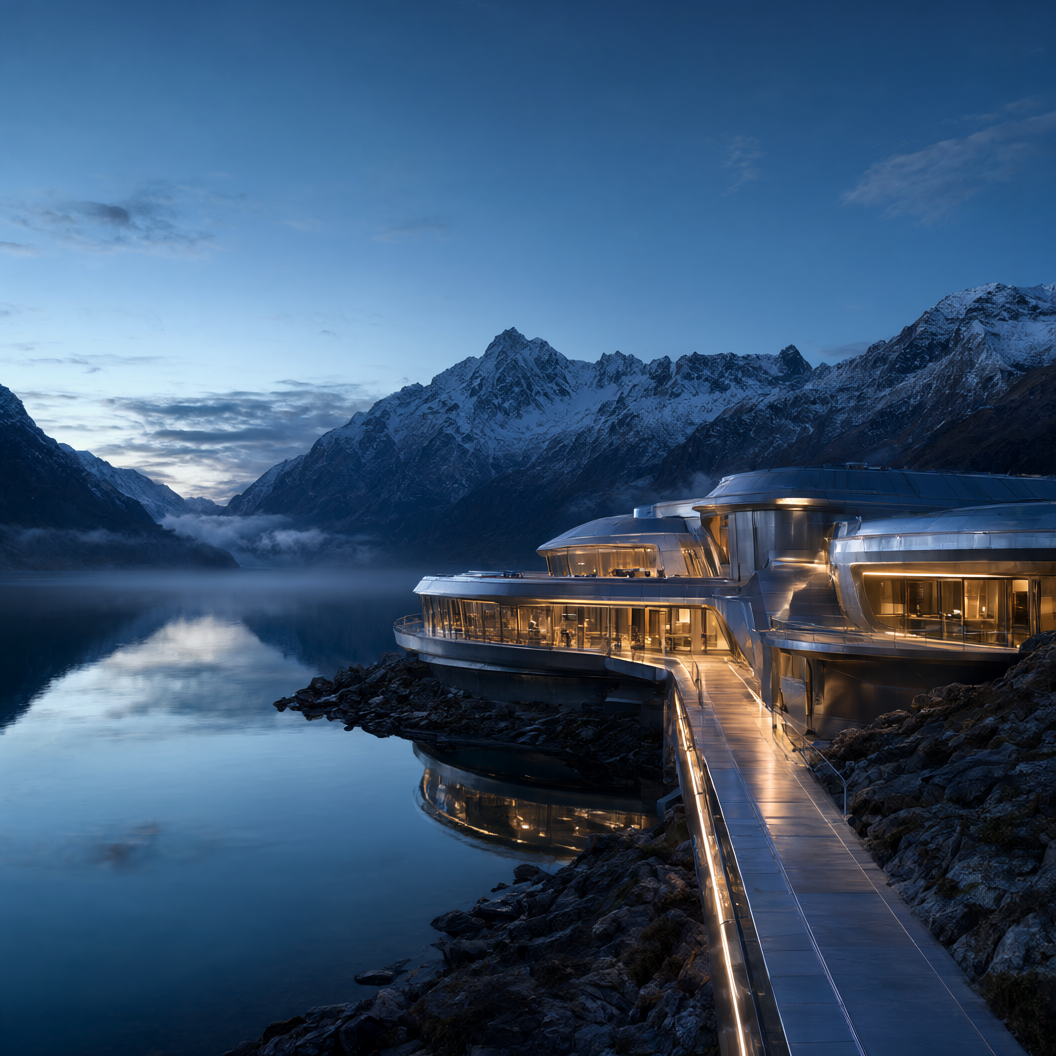

In [7]:
# @title 7. Prepare image and select a ratio/profile canvas
from PIL import Image, ImageOps
from IPython.display import display
import pathlib, os, math, uuid

display_image = True # @param {type:"boolean"}

if "INPUT_ORIGINAL_PATH" not in globals() or not os.path.isfile(INPUT_ORIGINAL_PATH):
    raise RuntimeError("Run the opening-image upload cell first.")
source = ImageOps.exif_transpose(Image.open(INPUT_ORIGINAL_PATH)).convert("RGB")
orig_w, orig_h = source.size
source_ar = float(orig_w) / float(orig_h)

# Approximate ratio families shown by the hosted MiniMax-H3 interface.
RATIO_FAMILIES = {
    "16:9 Landscape": 16.0 / 9.0,
    "9:16 Portrait": 9.0 / 16.0,
    "1:1 Square": 1.0,
    "4:3 Landscape": 4.0 / 3.0,
    "3:4 Portrait": 3.0 / 4.0,
    "21:9 Ultrawide": 21.0 / 9.0,
}
RATIO_KEYS = {
    "16:9 Landscape": "16:9",
    "9:16 Portrait": "9:16",
    "1:1 Square": "1:1",
    "4:3 Landscape": "4:3",
    "3:4 Portrait": "3:4",
    "21:9 Ultrawide": "21:9",
}

# Native tier sizes modeled on the visible presets in the reference UI.
# All values are divisible by 32 and are only the preset targets, not a promise of speed.
PROFILE_CANVASES = {
    "Fast (recommended for T4)": {
        "16:9": (960, 544),
        "9:16": (544, 960),
        "1:1": (544, 544),
        "4:3": (768, 576),
        "3:4": (576, 768),
        "21:9": (1152, 512),
    },
    "Medium (balanced automatic)": {
        "16:9": (1024, 576),
        "9:16": (640, 1152),
        "1:1": (768, 768),
        "4:3": (896, 672),
        "3:4": (672, 896),
        "21:9": (1280, 576),
    },
    "Full (higher detail)": {
        "16:9": (1344, 768),
        "9:16": (768, 1344),
        "1:1": (768, 768),
        "4:3": (1024, 768),
        "3:4": (768, 1024),
        "21:9": (1536, 672),
    },
}

# Fixed native canvases accepted by the optional remote conditioner.
REMOTE_CANVASES = {
    "960x544 · 16:9 fast": (960, 544),
    "1024x576 · 16:9 fast": (1024, 576),
    "1152x640 · 16:9": (1152, 640),
    "1280x704 · 16:9": (1280, 704),
    "1344x768 · 16:9 full": (1344, 768),
    "544x960 · 9:16 fast": (544, 960),
    "640x1152 · 9:16": (640, 1152),
    "768x1344 · 9:16 full": (768, 1344),
    "544x544 · 1:1 fast": (544, 544),
    "768x768 · 1:1 full": (768, 768),
    "1024x1024 · 1:1 max": (1024, 1024),
    "768x576 · 4:3 fast": (768, 576),
    "1024x768 · 4:3 full": (1024, 768),
    "576x768 · 3:4 fast": (576, 768),
    "768x1024 · 3:4 full": (768, 1024),
    "1152x512 · 21:9 fast": (1152, 512),
    "1536x672 · 21:9 full": (1536, 672),
}

REMOTE_RATIO_LABELS = {
    "16:9": [
        "960x544 · 16:9 fast", "1024x576 · 16:9 fast",
        "1152x640 · 16:9", "1280x704 · 16:9", "1344x768 · 16:9 full"
    ],
    "9:16": [
        "544x960 · 9:16 fast", "640x1152 · 9:16", "768x1344 · 9:16 full"
    ],
    "1:1": ["544x544 · 1:1 fast", "768x768 · 1:1 full", "1024x1024 · 1:1 max"],
    "4:3": ["768x576 · 4:3 fast", "1024x768 · 4:3 full"],
    "3:4": ["576x768 · 3:4 fast", "768x1024 · 3:4 full"],
    "21:9": ["1152x512 · 21:9 fast", "1536x672 · 21:9 full"],
}

def pick_ratio_key(img_w, img_h, ratio_mode):
    """Return the nearest supported ratio family, or a user-selected family."""
    if ratio_mode == "Auto (closest supported ratio)":
        ar = float(img_w) / float(img_h)
        return min(RATIO_FAMILIES, key=lambda name: abs(math.log(ar / RATIO_FAMILIES[name])))
    if ratio_mode not in RATIO_KEYS:
        raise ValueError(f"Unknown aspect ratio mode: {ratio_mode}")
    return ratio_mode

def _long_edge_limit(profile_dims, max_edge_setting):
    profile_edge = max(profile_dims)
    if str(max_edge_setting).strip().lower() in ("use profile size", "profile size", "auto"):
        return profile_edge, None
    try:
        hard_cap = int(max_edge_setting)
    except Exception as exc:
        raise ValueError(f"MAX_OUTPUT_LONG_EDGE must be 'Use profile size' or an integer, got {max_edge_setting!r}") from exc
    if hard_cap < 256:
        raise ValueError("MAX_OUTPUT_LONG_EDGE must be at least 256.")
    return min(profile_edge, hard_cap), hard_cap

def nearest_multiple_of_32(value, minimum=256):
    return max(minimum, int(round(float(value) / 32.0)) * 32)

def choose_local_canvas(target_ar, target_long_edge, max_edge_setting, min_edge=256, tolerance=0.02):
    """Choose the largest multiple-of-32 canvas under the effective edge limit and near target aspect."""
    effective_edge, hard_cap = _long_edge_limit((int(target_long_edge), int(target_long_edge)), max_edge_setting)
    edge32 = (int(effective_edge) // 32) * 32
    if edge32 < min_edge:
        raise ValueError(f"Effective output edge {effective_edge} is too small; choose at least {min_edge}.")
    candidates = []
    for w in range(min_edge, edge32 + 1, 32):
        for h in range(min_edge, edge32 + 1, 32):
            if max(w, h) > effective_edge:
                continue
            ar_error = abs(math.log((float(w) / float(h)) / float(target_ar)))
            candidates.append((ar_error, -(w * h), -max(w, h), w, h))
    acceptable = [c for c in candidates if c[0] <= math.log(1.0 + tolerance)]
    if acceptable:
        chosen = min(acceptable, key=lambda c: (c[1], c[0], c[2]))
    else:
        # Some aspect/cap combinations cannot meet the 2% tolerance under 32-pixel alignment.
        chosen = min(candidates, key=lambda c: (c[0], c[1], c[2]))
    return chosen[3], chosen[4], effective_edge, hard_cap

def choose_remote_canvas(ratio_key, profile, max_edge_setting):
    """Select only an actual remote dropdown preset; never silently exceed a numeric hard cap."""
    labels = REMOTE_RATIO_LABELS[ratio_key]
    family_ar = RATIO_FAMILIES[next(name for name, key in RATIO_KEYS.items() if key == ratio_key)]
    desired_w, desired_h = PROFILE_CANVASES[profile][ratio_key]
    desired_edge = max(desired_w, desired_h)
    if str(max_edge_setting).strip().lower() in ("use profile size", "profile size", "auto"):
        eligible = labels
    else:
        cap = int(max_edge_setting)
        eligible = [label for label in labels if max(REMOTE_CANVASES[label]) <= cap]
        if not eligible:
            smallest = min(max(REMOTE_CANVASES[label]) for label in labels)
            raise RuntimeError(
                f"The remote conditioner has no {ratio_key} preset at or below the {cap}px hard cap "
                f"(smallest matching remote preset has a {smallest}px long edge). "
                "Use Local ComfyUI text encoder mode for arbitrary capped dimensions, or raise MAX_OUTPUT_LONG_EDGE."
            )
    # Prefer the closest available size not larger than the profile target; otherwise use the closest size.
    not_above = [label for label in eligible if max(REMOTE_CANVASES[label]) <= desired_edge]
    pool = not_above or eligible
    chosen = min(
        pool,
        key=lambda label: (
            abs(math.log((REMOTE_CANVASES[label][0] / REMOTE_CANVASES[label][1]) / family_ar)),
            abs(max(REMOTE_CANVASES[label]) - desired_edge),
            -REMOTE_CANVASES[label][0] * REMOTE_CANVASES[label][1],
        )
    )
    w, h = REMOTE_CANVASES[chosen]
    if str(max_edge_setting).strip().lower() not in ("use profile size", "profile size", "auto") and max(w, h) > int(max_edge_setting):
        raise RuntimeError(f"Remote canvas {chosen} exceeds the selected hard cap.")
    return chosen, w, h

# Determine selected ratio family and the source/profile aspect targets.
ratio_family = pick_ratio_key(orig_w, orig_h, ASPECT_RATIO_MODE)
ratio_key = RATIO_KEYS[ratio_family]
profile_w, profile_h = PROFILE_CANVASES[RESOLUTION_PROFILE][ratio_key]
profile_long_edge = max(profile_w, profile_h)

# Manual size mode uses the manual dimensions as its requested canvas.
if OUTPUT_SIZE_MODE == "Manual width and height":
    requested_w = nearest_multiple_of_32(MANUAL_OUTPUT_WIDTH)
    requested_h = nearest_multiple_of_32(MANUAL_OUTPUT_HEIGHT)
    requested_ar = float(requested_w) / float(requested_h)
    requested_edge = max(requested_w, requested_h)
    if str(MAX_OUTPUT_LONG_EDGE).strip().lower() in ("use profile size", "profile size", "auto"):
        effective_limit = requested_edge
        hard_cap = None
    else:
        hard_cap = int(MAX_OUTPUT_LONG_EDGE)
        effective_limit = min(requested_edge, hard_cap)

    if CONDITIONING_BACKEND == LOCAL_CONDITIONING:
        OUTPUT_WIDTH, OUTPUT_HEIGHT, effective_edge, _ = choose_local_canvas(
            requested_ar, effective_limit, effective_limit
        )
        CONDITIONER_CANVAS = f"Local manual {OUTPUT_WIDTH}x{OUTPUT_HEIGHT}"
    else:
        manual_ratio_key = min(
            RATIO_FAMILIES,
            key=lambda name: abs(math.log(requested_ar / RATIO_FAMILIES[name]))
        )
        manual_key = RATIO_KEYS[manual_ratio_key]
        CONDITIONER_CANVAS, OUTPUT_WIDTH, OUTPUT_HEIGHT = choose_remote_canvas(
            manual_key, RESOLUTION_PROFILE, MAX_OUTPUT_LONG_EDGE
        )
        print("NOTE: remote conditioning uses a supported fixed canvas; manual dimensions are mapped to its closest ratio preset.")

elif OUTPUT_SIZE_MODE == "Automatic aspect/profile":
    target_ar = RATIO_FAMILIES[ratio_family]
    if CONDITIONING_BACKEND == LOCAL_CONDITIONING:
        OUTPUT_WIDTH, OUTPUT_HEIGHT, effective_edge, hard_cap = choose_local_canvas(
            target_ar, profile_long_edge, MAX_OUTPUT_LONG_EDGE
        )
        if hard_cap is None:
            cap_label = f"profile default ({profile_long_edge}px for {ratio_key})"
        else:
            cap_label = f"strict {hard_cap}px cap"
        CONDITIONER_CANVAS = f"Local {RESOLUTION_PROFILE} {ratio_key} auto {OUTPUT_WIDTH}x{OUTPUT_HEIGHT}"
    else:
        CONDITIONER_CANVAS, OUTPUT_WIDTH, OUTPUT_HEIGHT = choose_remote_canvas(
            ratio_key, RESOLUTION_PROFILE, MAX_OUTPUT_LONG_EDGE
        )
        effective_edge = max(OUTPUT_WIDTH, OUTPUT_HEIGHT)
        hard_cap = None if str(MAX_OUTPUT_LONG_EDGE).strip().lower() in ("use profile size", "profile size", "auto") else int(MAX_OUTPUT_LONG_EDGE)
        cap_label = f"remote preset ({effective_edge}px edge)"
else:
    raise ValueError(f"Unknown OUTPUT_SIZE_MODE: {OUTPUT_SIZE_MODE}")

input_scale = min(1.0, float(INPUT_IMAGE_MAX_LONG_EDGE) / max(orig_w, orig_h))
ref_w = max(1, int(round(orig_w * input_scale)))
ref_h = max(1, int(round(orig_h * input_scale)))
reference_image = source.resize((ref_w, ref_h), Image.Resampling.LANCZOS)
COMFY_INPUT_DIR = pathlib.Path(COMFY_ROOT) / "input"
COMFY_INPUT_DIR.mkdir(parents=True, exist_ok=True)
REFERENCE_FILENAME = f"h3_reference_{uuid.uuid4().hex[:10]}.png"
REFERENCE_PATH = COMFY_INPUT_DIR / REFERENCE_FILENAME
reference_image.save(REFERENCE_PATH, format="PNG", optimize=True)

def valid_h3_frames(seconds):
    raw = max(5, round(float(seconds) * 24))
    return raw + (5 - (raw % 17)) % 17
FRAME_COUNT = valid_h3_frames(DURATION_SECONDS)

print(f"Original image:          {orig_w} × {orig_h} (aspect {source_ar:.4f})")
print(f"Detected ratio family:   {ratio_family} ({RATIO_FAMILIES[ratio_family]:.4f})")
print(f"Resolution profile:      {RESOLUTION_PROFILE}")
print(f"Output size mode:        {OUTPUT_SIZE_MODE}")
print(f"Profile native canvas:   {profile_w} × {profile_h} (long edge {profile_long_edge})")
print(f"Maximum edge setting:    {MAX_OUTPUT_LONG_EDGE}")
print(f"Selected canvas:         {CONDITIONER_CANVAS}")
print(f"Output resolution:       {OUTPUT_WIDTH} × {OUTPUT_HEIGHT} (aspect {OUTPUT_WIDTH/OUTPUT_HEIGHT:.4f})")
print(f"Longest output edge:     {max(OUTPUT_WIDTH, OUTPUT_HEIGHT)} px")
if str(MAX_OUTPUT_LONG_EDGE).strip().lower() not in ("use profile size", "profile size", "auto"):
    if max(OUTPUT_WIDTH, OUTPUT_HEIGHT) > int(MAX_OUTPUT_LONG_EDGE):
        raise AssertionError("Internal resolution bug: output exceeded MAX_OUTPUT_LONG_EDGE.")
    print(f"Hard-cap check:          PASS (longest edge <= {int(MAX_OUTPUT_LONG_EDGE)} px)")
else:
    print(f"Profile edge limit:      {profile_long_edge}px (profile default)")
print(f"Requested duration:      {DURATION_SECONDS:.2f} s")
print(f"Valid H3 frame count:    {FRAME_COUNT} at 24 fps (~{FRAME_COUNT/24:.2f} s)")
print("Mode: I2VA / FL2VA — input image is the opening frame")
if display_image:
  display(reference_image)

In [8]:

# @title Install and repair Practical-RIFE 4.25
import os
import sys
import shutil
import subprocess
from pathlib import Path

RIFE_DIR = Path("/content/Practical-RIFE")
SOURCE_DIR = Path("/content/Practical-RIFE-source")
TRAIN_DIR = RIFE_DIR / "train_log"

MODEL_BASE = (
    "https://huggingface.co/Isi99999/"
    "Frame_Interpolation_Models/resolve/main/4.25/train_log"
)

def run(cmd, cwd=None):
    print("+", " ".join(map(str, cmd)))
    subprocess.run(
        list(map(str, cmd)),
        cwd=str(cwd) if cwd else None,
        check=True
    )

# FFmpeg is needed for video handling and audio muxing.
if shutil.which("ffmpeg") is None or shutil.which("ffprobe") is None:
    run(["apt-get", "update", "-qq"])
    run(["apt-get", "install", "-y", "-qq", "ffmpeg"])

# Obtain the real Practical-RIFE source tree.
if not (RIFE_DIR / ".git").exists() or not (
    RIFE_DIR / "model" / "warplayer.py"
).is_file():
    if SOURCE_DIR.exists():
        shutil.rmtree(SOURCE_DIR)

    run([
        "git", "clone", "--depth", "1",
        "https://github.com/Isi-dev/Practical-RIFE.git",
        str(SOURCE_DIR)
    ])

    # Preserve existing weights and files; copy actual source files.
    RIFE_DIR.mkdir(parents=True, exist_ok=True)

    for source in SOURCE_DIR.rglob("*"):
        rel = source.relative_to(SOURCE_DIR)

        # Do not copy Git metadata or replace the model files.
        if ".git" in rel.parts:
            continue

        destination = RIFE_DIR / rel

        if source.is_dir():
            destination.mkdir(parents=True, exist_ok=True)
        elif not destination.exists():
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source, destination)

    shutil.rmtree(SOURCE_DIR, ignore_errors=True)

TRAIN_DIR.mkdir(parents=True, exist_ok=True)

# The 4.25 architecture files and checkpoint belong in train_log/.
model_files = {
    "IFNet_HDv3.py": "IFNet_HDv3.py",
    "RIFE_HDv3.py": "RIFE_HDv3.py",
    "refine.py": "refine.py",
    "flownet.pkl": "flownet.pkl",
}

for filename, remote_name in model_files.items():
    destination = TRAIN_DIR / filename
    url = MODEL_BASE + "/" + remote_name

    if not destination.exists() or destination.stat().st_size == 0:
        print("Downloading:", filename)
        run([
            "wget", "-q", "--show-progress",
            url, "-O", str(destination)
        ])

# Ensure imports can resolve both the model package and train_log modules.
if str(RIFE_DIR) not in sys.path:
    sys.path.insert(0, str(RIFE_DIR))
if str(TRAIN_DIR) not in sys.path:
    sys.path.insert(0, str(TRAIN_DIR))

# Verify required files and reject HTML/error pages masquerading as downloads.
required = [
    RIFE_DIR / "model" / "warplayer.py",
    TRAIN_DIR / "IFNet_HDv3.py",
    TRAIN_DIR / "RIFE_HDv3.py",
    TRAIN_DIR / "refine.py",
    TRAIN_DIR / "flownet.pkl",
]

for path in required:
    if not path.is_file() or path.stat().st_size == 0:
        raise RuntimeError("Required RIFE file is missing or empty: " + str(path))

for filename in ("IFNet_HDv3.py", "RIFE_HDv3.py", "refine.py"):
    path = TRAIN_DIR / filename
    if path.read_bytes().lstrip().startswith(b"<!DOCTYPE html"):
        raise RuntimeError("Download returned HTML instead of Python: " + str(path))

# Test imports before running inference.
os.chdir(str(RIFE_DIR))

import torch
import cv2
from model.warplayer import warp
from RIFE_HDv3 import Model

print("\nRIFE imports successful.")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("RIFE source:", RIFE_DIR)
print("RIFE checkpoint:", TRAIN_DIR / "flownet.pkl")

+ git clone --depth 1 https://github.com/Isi-dev/Practical-RIFE.git /content/Practical-RIFE-source
Downloading: IFNet_HDv3.py
+ wget -q --show-progress https://huggingface.co/Isi99999/Frame_Interpolation_Models/resolve/main/4.25/train_log/IFNet_HDv3.py -O /content/Practical-RIFE/train_log/IFNet_HDv3.py
Downloading: RIFE_HDv3.py
+ wget -q --show-progress https://huggingface.co/Isi99999/Frame_Interpolation_Models/resolve/main/4.25/train_log/RIFE_HDv3.py -O /content/Practical-RIFE/train_log/RIFE_HDv3.py
Downloading: refine.py
+ wget -q --show-progress https://huggingface.co/Isi99999/Frame_Interpolation_Models/resolve/main/4.25/train_log/refine.py -O /content/Practical-RIFE/train_log/refine.py
Downloading: flownet.pkl
+ wget -q --show-progress https://huggingface.co/Isi99999/Frame_Interpolation_Models/resolve/main/4.25/train_log/flownet.pkl -O /content/Practical-RIFE/train_log/flownet.pkl

RIFE imports successful.
PyTorch: 2.11.0+cu130
CUDA available: True
RIFE source: /content/Practical-R

In [9]:

# @title Create corrected RIFE inference script
from pathlib import Path

RIFE_DIR = Path("/content/Practical-RIFE")
script_path = RIFE_DIR / "inference_video.py"

inference_script = r'''
import os
import sys
import time
import argparse

BASE = os.path.dirname(os.path.abspath(__file__))
TRAIN_DIR = os.path.join(BASE, "train_log")

sys.path.insert(0, BASE)
sys.path.insert(0, TRAIN_DIR)
os.chdir(BASE)

import cv2
import numpy as np
import torch
from torch.nn import functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def make_inference(model, I0, I1, n):
    if n <= 1:
        return []

    if getattr(model, "version", 0) >= 3.9:
        mid = model.inference(I0, I1, 0.5, 1.0)
    else:
        mid = model.inference(I0, I1)

    return (
        make_inference(model, I0, mid, n // 2)
        + [mid]
        + make_inference(model, mid, I1, n // 2)
    )

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--video", required=True)
    parser.add_argument("--output", required=True)
    parser.add_argument("--multi", type=int, default=2)
    parser.add_argument("--scale", type=float, default=1.0)
    args = parser.parse_args()

    if args.multi not in (2, 4, 8):
        raise ValueError("--multi must be 2, 4, or 8")
    if not os.path.isfile(args.video):
        raise FileNotFoundError(args.video)

    # Import from train_log and load weights from train_log.
    from RIFE_HDv3 import Model

    model = Model()
    model.load_model(TRAIN_DIR, -1)
    model.eval()
    model.device()

    print("RIFE model loaded successfully.")

    cap = cv2.VideoCapture(args.video)
    if not cap.isOpened():
        raise RuntimeError("Could not open input video: " + args.video)

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps <= 0:
        fps = 24.0

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    out_w = max(1, int(round(width * args.scale)))
    out_h = max(1, int(round(height * args.scale)))

    # RIFE expects spatial dimensions aligned to multiples of 64.
    padded_w = ((out_w + 63) // 64) * 64
    padded_h = ((out_h + 63) // 64) * 64
    padding = (0, padded_w - out_w, 0, padded_h - out_h)

    os.makedirs(os.path.dirname(os.path.abspath(args.output)), exist_ok=True)
    writer = cv2.VideoWriter(
        args.output,
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps * args.multi,
        (out_w, out_h)
    )

    if not writer.isOpened():
        cap.release()
        raise RuntimeError("Could not create output video: " + args.output)

    last = None
    processed = 0
    started = time.time()

    try:
        with torch.inference_mode():
            while True:
                ok, frame = cap.read()
                if not ok:
                    break

                frame = cv2.resize(frame, (out_w, out_h))
                current = torch.from_numpy(
                    np.ascontiguousarray(frame.transpose(2, 0, 1))
                ).to(device).unsqueeze(0).float() / 255.0

                current = F.pad(current, padding)

                if last is not None:
                    mids = make_inference(model, last, current, args.multi)

                    for mid in mids:
                        out = mid[0, :, :out_h, :out_w]
                        out = (out.clamp(0, 1) * 255).byte()
                        out = out.cpu().numpy().transpose(1, 2, 0)
                        writer.write(np.ascontiguousarray(out))

                # Write each original frame as well.
                writer.write(frame)
                last = current
                processed += 1

                if processed % 10 == 0:
                    print("Processed {}/{}".format(processed, total))

    finally:
        cap.release()
        writer.release()

    if processed == 0:
        raise RuntimeError("No frames were read from the input video.")

    print("Finished processing {} frames in {:.1f}s".format(
        processed, time.time() - started
    ))
    print("Silent interpolated video:", args.output)

if __name__ == "__main__":
    main()
'''

script_path.write_text(inference_script, encoding="utf-8")
print("Created:", script_path)

Created: /content/Practical-RIFE/inference_video.py


## 8. Preflight and generate with ComfyUI

Run preflight first, then generation. The **video transformer, VAEs, sampling, LoRA application, and MP4 saving run locally through ComfyUI**. With remote conditioning selected, only Qwen3-VL prompt/image conditioning uses a Hugging Face Space; with local encoder selected, there is no remote GPU call.

Larry's Turbo LoRA is handled by its dedicated node and sampler at 7 steps. Selected optional compatible/style adapters are applied one by one using the standard ComfyUI model-only LoRA loader; they are not merged with Turbo into an artificial combined file. GGUF + LoRA patching is experimental in ComfyUI-GGUF, and not every Space catalogue entry is guaranteed to match the local model keys.


In [16]:
# @title 8. Preflight: verify local ComfyUI nodes
import requests, pathlib, os
COMFY_URL = "http://127.0.0.1:8188"
LOG_PATH = pathlib.Path("/content/comfyui_h3_local.log")
try:
    health = requests.get(f"{COMFY_URL}/system_stats", timeout=8)
    health.raise_for_status()
except requests.RequestException as exc:
    tail = ""
    try:
        tail = "\n".join(LOG_PATH.read_text(errors="replace").splitlines()[-80:])
    except Exception:
        tail = "(No backend log file found.)"
    process_status = "unknown"
    try:
        process_status = str(comfy_process.poll()) if "comfy_process" in globals() else "no comfy_process variable in this runtime"
    except Exception:
        pass
    raise RuntimeError(
        "ComfyUI is not reachable at 127.0.0.1:8188. This is a backend startup/exit problem, "
        "not a prompt or LoRA error. Process exit status: " + process_status +
        ". Rerun Cell 5 (Start/restart local ComfyUI backend), then retry this cell.\n\nRecent backend log:\n" + tail[-7000:]
    ) from exc
health.raise_for_status()
object_info = requests.get(f"{COMFY_URL}/object_info", timeout=60).json()
print("ComfyUI API ready:", COMFY_URL)
print("Registered node classes:", len(object_info))
for cls in ("UnetLoaderGGUF", "MiniMaxH3ImageToVideo", "LoraLoaderModelOnly"):
    print(cls + ":", cls in object_info)
if CONDITIONING_BACKEND == REMOTE_CONDITIONING:
    print("MiniMaxH3RemoteConditioning:", "MiniMaxH3RemoteConditioning" in object_info)
else:
    print("Local encoder file:", (pathlib.Path(TEXT_ENCODER_DIR) / TEXT_ENCODER_FILE).is_file())
print("Conditioning backend:", CONDITIONING_BACKEND)

print("Active diffusion model:", DIFFUSION_FILE)

ComfyUI API ready: http://127.0.0.1:8188
Registered node classes: 1281
UnetLoaderGGUF: True
MiniMaxH3ImageToVideo: True
LoraLoaderModelOnly: True
MiniMaxH3RemoteConditioning: True
Conditioning backend: Remote Qwen3-VL conditioner (lower T4 memory; may hit Space quota)
Active diffusion model: minimax_h3_fl2va_pruned_fp8_Q4_0.gguf


In [18]:
# @title 9. Generate video in this notebook
import os, sys, time, json, uuid, secrets, pathlib, shutil, requests, re, hashlib, urllib.parse
from IPython.display import display, Video, Markdown
from huggingface_hub import hf_hub_download, HfApi
from gradio_client import Client, handle_file
import hashlib

COMFY_URL = "http://127.0.0.1:8188"
API_WORKFLOW_URL = (
    "https://raw.githubusercontent.com/TheTerrasque/minimax-h3-frontend/"
    "main/resources/workflows_api/video_minimax_h3_i2v.api.json"
)
OUTPUT_DIR = pathlib.Path("/content/h3_notebook_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LARRY_REPO = "larryvrh/MiniMax-H3-Turbo-Lora"
LARRY_FILE = "minimax_h3_turbo_v4_step600_ema.safetensors"
DEFAULT_H3_LORA_REPO = None

def ensure_turbo_lora():
    """Download only the dedicated Turbo adapter used by this public workflow."""
    target_dir = pathlib.Path(LORA_DIR)
    target_dir.mkdir(parents=True, exist_ok=True)
    target = target_dir / LARRY_FILE
    if target.is_file() and target.stat().st_size > 0:
        print("Turbo adapter cached:", target.name)
        return target
    token = (HF_TOKEN or "").strip() or None
    downloaded = hf_hub_download(
        repo_id=LARRY_REPO, filename=LARRY_FILE, token=token
    )
    shutil.copy2(downloaded, target)
    print("Downloaded dedicated Turbo adapter:", target.name)
    return target

def nodes_of_type(wf, types):
    return [(str(node_id), node) for node_id, node in wf.items()
            if isinstance(node, dict) and node.get("class_type") in types]

def is_link(value, wf):
    return isinstance(value, list) and len(value) == 2 and str(value[0]) in wf

def upstream_load_image(wf, node_id, visited=None):
    if visited is None:
        visited = set()
    node_id = str(node_id)
    if node_id in visited or node_id not in wf:
        return None
    visited.add(node_id)
    node = wf[node_id]
    if node.get("class_type") == "LoadImage":
        return node_id
    for value in node.get("inputs", {}).values():
        if is_link(value, wf):
            found = upstream_load_image(wf, str(value[0]), visited)
            if found is not None:
                return found
    return None

def set_node_value_or_upstream(wf, node_id, input_name, value):
    """Change a direct widget value or the PrimitiveInt/String node feeding it."""
    node = wf[str(node_id)]
    current = node.setdefault("inputs", {}).get(input_name)
    if is_link(current, wf):
        source = wf[str(current[0])]
        src_type = source.get("class_type", "")
        if src_type in ("PrimitiveInt", "PrimitiveFloat", "PrimitiveString", "PrimitiveStringMultiline"):
            source.setdefault("inputs", {})["value"] = value
        else:
            node["inputs"][input_name] = value
    else:
        node.setdefault("inputs", {})[input_name] = value

def set_steps(wf, steps):
    schedulers = nodes_of_type(wf, {"BasicScheduler"})
    for nid, node in schedulers:
        set_node_value_or_upstream(wf, nid, "steps", int(steps))
    # A few API workflow versions expose steps through direct primitive nodes only.
    if not schedulers:
        for _, node in nodes_of_type(wf, {"PrimitiveInt"}):
            title = str(node.get("_meta", {}).get("title", "")).lower()
            if "step" in title:
                node.setdefault("inputs", {})["value"] = int(steps)

def next_node_id(wf):
    numeric_prefixes = []
    for key in wf:
        try:
            numeric_prefixes.append(int(str(key).split(":")[0]))
        except Exception:
            pass
    candidate = max(numeric_prefixes + [0]) + 1
    while str(candidate) in wf:
        candidate += 1
    return str(candidate)

def get_default_from_schema(spec):
    if not isinstance(spec, list) or not spec:
        return None
    choices = spec[0]
    options = spec[1] if len(spec) > 1 and isinstance(spec[1], dict) else {}
    if isinstance(choices, list):
        return options.get("default", choices[0] if choices else None)
    kind = str(choices).upper()
    if kind == "BOOLEAN":
        return options.get("default", False)
    if kind == "INT":
        return options.get("default", options.get("min", 0))
    if kind == "FLOAT":
        return options.get("default", options.get("min", 0.0))
    if kind in ("STRING", "COMBO"):
        return options.get("default", "")
    return None

def make_lora_node_inputs(object_info, class_type, source_model_link, filename, weight, low_vram):
    schema = object_info[class_type].get("input", {})
    required = schema.get("required", {})
    optional = schema.get("optional", {})
    values = {}
    for key, spec in list(required.items()) + list(optional.items()):
        k = key.lower()
        if k == "model":
            values[key] = source_model_link
        elif "lora" in k and ("name" in k or "file" in k):
            values[key] = filename
        elif k in ("lora_name", "adapter_name", "filename"):
            values[key] = filename
        elif "strength" in k or "weight" in k:
            values[key] = float(weight)
        elif "low_vram" in k or "lowvram" in k:
            values[key] = bool(low_vram)
        else:
            default = get_default_from_schema(spec)
            if default is not None:
                values[key] = default
    if "model" not in values:
        raise RuntimeError(f"Cannot construct {class_type}: no MODEL input found. Schema keys: {list(required)}")
    # Ensure file/strength keys were populated even when the schema names differ.
    file_keys = [k for k in values if any(x in k.lower() for x in ("lora_name", "adapter_name", "filename"))]
    if not file_keys:
        raise RuntimeError(f"Cannot identify LoRA filename input for {class_type}. Schema keys: {list(required)}")
    return values

def add_model_adapter(wf, source_model_id, class_type, inputs, title):
    node_id = next_node_id(wf)
    wf[node_id] = {
        "class_type": class_type,
        "inputs": inputs,
        "_meta": {"title": title},
    }
    source_model_id = str(source_model_id)
    # Rewire direct consumers of the previous model output to the adapter output.
    for other_id, node in wf.items():
        if str(other_id) == node_id or not isinstance(node, dict):
            continue
        for key, value in list(node.get("inputs", {}).items()):
            if is_link(value, wf) and str(value[0]) == source_model_id and value[1] == 0:
                node["inputs"][key] = [node_id, 0]
    return node_id

def add_turbo_sampler(wf, object_info):
    sampler_classes = [
        key for key, spec in object_info.items()
        if "turbo" in key.lower() and "sampler" in key.lower()
    ]
    if not sampler_classes:
        raise RuntimeError("Larry's H3 Turbo Sampler node is missing from /object_info. Check the ComfyUI startup log.")
    sampler_cls = sampler_classes[0]
    node_id = next_node_id(wf)
    wf[node_id] = {"class_type": sampler_cls, "inputs": {}, "_meta": {"title": "H3 Turbo Sampler"}}

    custom_samplers = [
        (nid, node) for nid, node in wf.items()
        if isinstance(node, dict) and node.get("class_type") in {"SamplerCustomAdvanced", "SamplerCustom"}
    ]
    if not custom_samplers:
        raise RuntimeError("No SamplerCustomAdvanced/SamplerCustom node found to connect to H3 Turbo Sampler.")
    for _, node in custom_samplers:
        if "sampler" in node.setdefault("inputs", {}):
            node["inputs"]["sampler"] = [node_id, 0]
    return sampler_cls, node_id

# Check the backend before downloading adapters or calling the remote conditioner.
LOG_PATH = pathlib.Path("/content/comfyui_h3_local.log")
try:
    _health = requests.get(f"{COMFY_URL}/system_stats", timeout=8)
    _health.raise_for_status()
except requests.RequestException as exc:
    _tail = ""
    try: _tail = "\n".join(LOG_PATH.read_text(errors="replace").splitlines()[-80:])
    except Exception: _tail = "(No backend log file found.)"
    _process_state = str(comfy_process.poll()) if "comfy_process" in globals() else "backend process state unavailable"
    raise RuntimeError(
        "ComfyUI is not listening at 127.0.0.1:8188. The backend may have exited, been OOM-killed, "
        "or not been started in this runtime. Rerun Cell 5 (Start/restart local ComfyUI backend), "
        "then rerun the preflight cell. Process poll status: " + _process_state +
        "\n\nRecent backend log:\n" + _tail[-7000:]
    ) from exc

# Query node schemas from this exact running ComfyUI instance. The loader checks
# and Turbo-node construction below must use the live registry, not notebook leftovers.
object_info = requests.get(
    f"{COMFY_URL}/object_info",
    timeout=60,
).json()
print("Live ComfyUI node schema loaded:", len(object_info), "node classes")

# Public version: optional behavior/anatomy adapters are intentionally not loaded.
selected_loras = []
print("Optional behavior/anatomy LoRAs: disabled in public version.")

# Refuse to queue a high-memory Q5_0 run unless the user explicitly acknowledged the T4 risk.
if "Q5_0" in DIFFUSION_FILE and not ALLOW_Q5_T4_MEMORY_RISK:
    raise RuntimeError(
        "Q5_0 is blocked on the default T4 configuration to prevent an avoidable OOM. "
        "Select the recommended U16G model, or explicitly set ALLOW_Q5_T4_MEMORY_RISK=True in Cell 1 to override."
    )

# 1. Download the official API-format I2VA workflow.
# If the direct path changes, discover an I2V API workflow from the repository.
resp = requests.get(API_WORKFLOW_URL, timeout=60)
if resp.status_code == 404:
    listing_url = "https://api.github.com/repos/TheTerrasque/minimax-h3-frontend/contents/resources/workflows_api"
    listing_resp = requests.get(listing_url, timeout=60)
    listing_resp.raise_for_status()
    entries = listing_resp.json()
    matches = [
        item for item in entries
        if item.get("type") == "file"
        and "i2v" in item.get("name", "").lower()
        and item.get("name", "").lower().endswith(".api.json")
    ]
    if not matches:
        raise RuntimeError(
            "The expected I2VA API workflow URL returned 404, and no *.api.json I2V workflow "
            "was found under resources/workflows_api. Check the upstream repository."
        )
    matches.sort(key=lambda item: (item.get("name") != "video_minimax_h3_i2v.api.json", item.get("name")))
    API_WORKFLOW_URL = matches[0]["download_url"]
    print("Workflow filename changed upstream; using discovered file:", matches[0]["name"])
    resp = requests.get(API_WORKFLOW_URL, timeout=60)

resp.raise_for_status()
workflow = resp.json()
if not isinstance(workflow, dict) or not workflow:
    raise RuntimeError("The downloaded H3 API workflow is empty or is not API format.")

# 2. Validate source workflow and local node schemas.
h3_nodes = nodes_of_type(workflow, {"MiniMaxH3ImageToVideo"})
if len(h3_nodes) != 1:
    found = sorted(set(node.get("class_type", "?") for node in workflow.values() if isinstance(node, dict)))
    raise RuntimeError(f"Expected one MiniMaxH3ImageToVideo node, found {len(h3_nodes)}. Node types: {found[:80]}")
h3_id, h3_node = h3_nodes[0]
save_nodes = nodes_of_type(workflow, {"SaveVideo"})
if not save_nodes:
    raise RuntimeError("Workflow has no SaveVideo node.")
save_id = save_nodes[-1][0]

# 3. Use the local GGUF FL2VA transformer.
unet_nodes = nodes_of_type(workflow, {"UNETLoader", "UnetLoaderGGUF"})
if len(unet_nodes) != 1:
    raise RuntimeError(f"Expected one diffusion-model loader, found {[n for n, _ in unet_nodes]}.")
unet_id, unet_node = unet_nodes[0]
if "UnetLoaderGGUF" not in object_info:
    raise RuntimeError("UnetLoaderGGUF is not registered. Check the GGUF node fork and startup log.")
unet_node["class_type"] = "UnetLoaderGGUF"
unet_node["inputs"] = {"unet_name": DIFFUSION_FILE}

if "MiniMaxH3RemoteConditioning" not in object_info:
    raise RuntimeError("MiniMaxH3RemoteConditioning is missing from /object_info. Run the installer, then restart ComfyUI.")

# 5. Patch VAEs, distinguishing audio from video by node title/input name.
vae_nodes = nodes_of_type(workflow, {"VAELoader"})
if len(vae_nodes) < 2:
    raise RuntimeError(f"Expected separate video and audio VAE loaders, found {len(vae_nodes)}.")
for _, node in vae_nodes:
    inp = node.setdefault("inputs", {})
    title = str(node.get("_meta", {}).get("title", "")).lower()
    old_name = str(inp.get("vae_name", "")).lower()
    if "audio" in title or "audio" in old_name:
        inp["vae_name"] = AUDIO_VAE_FILE
    else:
        inp["vae_name"] = VIDEO_VAE_FILE

# 6. Set the opening image and compose a natural-language request for remote Qwen3-VL.
first_frame_link = h3_node.get("inputs", {}).get("first_frame")
if not is_link(first_frame_link, workflow):
    raise RuntimeError("I2VA workflow has no connected first_frame input.")
first_frame_loader_id = upstream_load_image(workflow, str(first_frame_link[0]))
if first_frame_loader_id is None:
    raise RuntimeError("Could not trace first_frame to its LoadImage node.")
workflow[first_frame_loader_id].setdefault("inputs", {})["image"] = REFERENCE_FILENAME
h3_node.setdefault("inputs", {}).pop("last_frame", None)

action = PROMPT.strip()
enforce_public_prompt_policy(action, label="video prompt")
if not action:
    raise ValueError("PROMPT is empty. Describe the intended action/camera movement.")
# Screen the uploaded reference image before using it as conditioning.
moderate_image_file(REFERENCE_PATH, label="uploaded opening frame")
subject_notes = SUBJECT_NOTES.strip()
subject_constraint = (
    "Additional appearance constraints from the user: " + subject_notes + ". "
    if subject_notes else
    "Preserve the subject's recognizable identity, face, visible proportions, hair, clothing/materials, colours, lighting, and background unless the requested action explicitly changes them. "
)
lora_trigger_line = ""
lora_constraint = ""
audio_text = AUDIO_DIRECTION.strip() or (
    "Generate natural ambience and sound effects that match the "
    "visible events and timing. Do not narrate, read, repeat, or "
    "paraphrase the user's video prompt. Do not add explanatory "
    "voice-over or invented dialogue."
)

music_text = MUSIC_DIRECTION.strip() or (
    "Use subtle, scene-appropriate background music when suitable. "
    "Keep music secondary to natural sounds. Do not turn the user's "
    "video prompt into spoken words or lyrics."
)
raw_prompt = (
    action + " " + lora_trigger_line + lora_constraint + subject_constraint +
    " Keep movement continuous, physically plausible, and temporally coherent. " +
    "Sound design: " + audio_text + " Music: " + music_text
)

# MiniMax-H3 I2VA alignment header as used by the official conditioner rewriter.
i2va_header = (
    "For the target video, at 0.00 seconds into the target video, "
    "<Picture 1> (from [Shot 1]) is fully referenced."
)

if PROMPT_PROCESSING_MODE == "Action-locked H3 template (recommended)":
    # Deterministic H3 structure. The user's actual requested action is copied verbatim into the text
    # that will be encoded. The visual reference remains available as the image input to Qwen3-VL.
    prompt_to_encode = (
        i2va_header + "\n\n"
        "integrated_multimodal_description: [Shot 1] Begin from the exact opening image <Picture 1>. "
        "The user's requested action and camera direction are the primary instructions and must be carried out as specified. "
        "User-requested action (preserve this wording and intent; do not replace, weaken, omit, or generalize it): "
        + action + " " + lora_trigger_line + lora_constraint + subject_constraint +
        "Treat visual continuity and appearance notes as supporting constraints, not as replacements for the requested action. "
        "Use one continuous shot unless the user explicitly requests cuts. Keep the movement physically coherent and temporally continuous.\n\n"
        "overall_soundscape: " + audio_text + "\n\n"
        "non_diegetic_music: " + music_text
    )
    rewrite_enabled = False
elif PROMPT_PROCESSING_MODE == "Remote Qwen rewrite (image-aware, may paraphrase)":
    prompt_to_encode = raw_prompt
    rewrite_enabled = True
elif PROMPT_PROCESSING_MODE == "Direct raw request (no rewrite)":
    prompt_to_encode = raw_prompt
    rewrite_enabled = False
else:
    raise ValueError("Unknown PROMPT_PROCESSING_MODE: " + str(PROMPT_PROCESSING_MODE))

if CONDITIONING_BACKEND == REMOTE_CONDITIONING and CONDITIONER_USE_PERSONAL_ZEROGPU_QUOTA and not HF_TOKEN:
    raise RuntimeError(
        "CONDITIONER_USE_PERSONAL_ZEROGPU_QUOTA is enabled, but HF_TOKEN is missing. "
        "Disable that option to use the anonymous/Space-IP quota path, or add the HF_TOKEN Colab Secret."
    )

if CONDITIONING_BACKEND == REMOTE_CONDITIONING:
    print("\n========== USER ACTION (LOCKED INPUT) ==========")
    print(action)
    print("\n========== PROMPT SENT TO REMOTE CONDITIONER ==========")
    print(prompt_to_encode)
    print("========================================================")
    print("Conditioner Space:", CONDITIONER_SPACE)
    print("Canvas:", CONDITIONER_CANVAS, "Frames:", FRAME_COUNT)
    print("Prompt processing mode:", PROMPT_PROCESSING_MODE)
    print("Remote free-form rewrite enabled:", rewrite_enabled)
    print("Selected adapter triggers included: none (optional adapters disabled)")

    # Cache embeddings for the exact image + encoded prompt + conditioner plan. This allows changing
    # seed/LoRAs/sampling settings without spending another remote ZeroGPU call for identical conditioning.
    CONDITIONING_CACHE_DIR = pathlib.Path("/content/h3_conditioning_cache")
    CONDITIONING_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    reference_sha256 = hashlib.sha256(pathlib.Path(REFERENCE_PATH).read_bytes()).hexdigest()
    cache_identity = {
        "cache_schema": 1,
        "conditioner_space": CONDITIONER_SPACE,
        "prompt_to_encode": prompt_to_encode,
        "rewrite_enabled": bool(rewrite_enabled),
        "canvas": str(CONDITIONER_CANVAS),
        "num_frames": int(FRAME_COUNT),
        "reference_sha256": reference_sha256,
    }
    cache_key = hashlib.sha256(json.dumps(cache_identity, sort_keys=True, ensure_ascii=False).encode("utf-8")).hexdigest()[:32]
    cached_embedding_path = CONDITIONING_CACHE_DIR / f"{cache_key}.safetensors"
    cached_plan_path = CONDITIONING_CACHE_DIR / f"{cache_key}.json"

    if cached_embedding_path.is_file() and cached_embedding_path.stat().st_size > 0 and cached_plan_path.is_file():
        conditioning_path = str(cached_embedding_path.resolve())
        conditioning_plan = json.loads(cached_plan_path.read_text(encoding="utf-8"))
        print("\nUsing cached remote conditioning; no ZeroGPU request was made:", cached_embedding_path.name)
    else:
        # HF_TOKEN is kept for downloads, but intentionally is NOT forwarded to the public conditioner
        # by default. The Space's app.py distinguishes a caller-token quota from its own IP quota.
        conditioner_token = HF_TOKEN if CONDITIONER_USE_PERSONAL_ZEROGPU_QUOTA else None
        quota_mode = "personal HF account quota" if conditioner_token else "anonymous / Space IP quota"
        print("\nRequesting conditioning via:", quota_mode)

        def _conditioner_predict(token_for_call):
            client = Client(CONDITIONER_SPACE, token=token_for_call, verbose=True)
            return client.predict(
                prompt_to_encode,
                handle_file(str(REFERENCE_PATH)),
                None,
                CONDITIONER_CANVAS,
                int(FRAME_COUNT),
                bool(rewrite_enabled),
                api_name="/encode",
            )

        def _is_zerogpu_quota_error(exc):
            message = str(exc).casefold()
            return "zerogpu" in message and ("quota" in message or "limit" in message)

        try:
            conditioning_path, conditioning_plan = _conditioner_predict(conditioner_token)
        except Exception as exc:
            # If a token-explicit call was chosen and the personal quota is exhausted, retry once
            # anonymously. This is the documented route used by other split H3 deployments.
            if conditioner_token and _is_zerogpu_quota_error(exc):
                print("Personal ZeroGPU quota was rejected. Retrying once without forwarding HF_TOKEN, using the Space IP quota.")
                try:
                    conditioning_path, conditioning_plan = _conditioner_predict(None)
                except Exception as anonymous_exc:
                    if _is_zerogpu_quota_error(anonymous_exc):
                        raise RuntimeError(
                            "The conditioner also rejected the anonymous/Space-IP quota request. This is a remote service quota limit, "
                            "not a local T4 or prompt error. Wait for the ZeroGPU quota window to reset, reuse a cached conditioning "
                            "result, or configure a separately paid/self-hosted conditioner. The 33B encoder is not installed locally. "
                            f"Anonymous request error: {anonymous_exc}"
                        ) from anonymous_exc
                    raise
            elif _is_zerogpu_quota_error(exc):
                raise RuntimeError(
                    "The public conditioner rejected the anonymous/Space-IP quota request. This is a remote service quota limit, "
                    "not a local T4 or prompt error. There is no valid notebook-side retry that can create new embeddings without "
                    "a functioning conditioner. Wait for the service quota window to reset, reuse cached conditioning for an identical "
                    "image/prompt/settings combination, or configure a separately paid/self-hosted conditioner. "
                    f"Remote error: {exc}"
                ) from exc
            else:
                raise

        conditioning_path = str(pathlib.Path(conditioning_path).resolve())
        if not pathlib.Path(conditioning_path).is_file():
            raise FileNotFoundError("The conditioner did not return a local safetensors file: " + conditioning_path)
        # Save a stable local copy; the Gradio client's temporary download path is not a reliable cache.
        shutil.copy2(conditioning_path, cached_embedding_path)
        cached_plan_path.write_text(json.dumps(conditioning_plan, ensure_ascii=False, indent=2), encoding="utf-8")
        conditioning_path = str(cached_embedding_path.resolve())
        print("Cached conditioning for future exact-match reuse:", cached_embedding_path.name)

    # Use the returned plan as the source of truth for size and valid frame count.
    OUTPUT_WIDTH = int(conditioning_plan["width"])
    OUTPUT_HEIGHT = int(conditioning_plan["height"])
    FRAME_COUNT = int(conditioning_plan["num_frames"])
    print("\nRemote conditioner plan:")
    print(json.dumps(conditioning_plan, indent=2, ensure_ascii=False))
    if conditioning_plan.get("refined_prompt"):
        print("\n========== QWEN-REWRITTEN H3 PROMPT ==========")
        print(conditioning_plan["refined_prompt"])
        print("==============================================\n")
    elif PROMPT_PROCESSING_MODE == "Action-locked H3 template (recommended)":
        print("\nAction-locked structured prompt was encoded as shown above; no rewriter paraphrase was applied.\n")

    # Drop local CLIP encoding and inject the remote tensors through the custom node.
    clip_link = h3_node.setdefault("inputs", {}).pop("clip", None)
    if is_link(clip_link, workflow):
        clip_id = str(clip_link[0])
        clip_node = workflow.get(clip_id, {})
        if clip_node.get("class_type") in {"CLIPLoader", "CLIPLoaderGGUF", "VideoCLIPLoaderGGUF"}:
            workflow.pop(clip_id, None)
    h3_node["class_type"] = "MiniMaxH3RemoteConditioning"
    h3_node["inputs"]["embedding_path"] = conditioning_path
    h3_node["inputs"].pop("prompt", None)  # Encoded remotely; this node has no local prompt input.
    h3_node["inputs"].pop("last_frame", None)
    h3_node["inputs"]["width"] = OUTPUT_WIDTH
    h3_node["inputs"]["height"] = OUTPUT_HEIGHT
    h3_node["inputs"]["length"] = FRAME_COUNT
    h3_node.setdefault("_meta", {})["title"] = "MiniMax H3 Remote Conditioning"
    print("Conditioning bridge node:", h3_id)
    print("Local first-frame node:", first_frame_loader_id)
    print("Embedding file:", conditioning_path)
else:
    # Local native ComfyUI encoder path: no call to Hugging Face Spaces/ZeroGPU.
    if PROMPT_PROCESSING_MODE == "Remote Qwen rewrite (image-aware, may paraphrase)":
        raise ValueError("Remote Qwen rewriting only applies in Remote Qwen3-VL conditioner mode. Select Action-locked or Direct raw request for local encoding.")
    encoder_path = pathlib.Path(TEXT_ENCODER_DIR) / TEXT_ENCODER_FILE
    if not encoder_path.is_file():
        raise FileNotFoundError(
            f"Local text encoder missing: {encoder_path}. Set CONDITIONING_BACKEND to Local in Cell 1, then rerun the model-download and backend-start cells."
        )
    clip_link = h3_node.setdefault("inputs", {}).get("clip")
    if not is_link(clip_link, workflow):
        raise RuntimeError("The downloaded I2VA workflow has no connected CLIP input on MiniMaxH3ImageToVideo; cannot use local encoder mode.")
    clip_loader_id = str(clip_link[0])
    clip_loader_node = workflow[clip_loader_id]
    if "CLIPLoader" not in object_info:
        raise RuntimeError("Native ComfyUI CLIPLoader is not registered, so local Qwen3-VL encoding is unavailable in this ComfyUI build.")
    clip_schema = object_info["CLIPLoader"].get("input", {})
    required_clip_inputs = clip_schema.get("required", {})
    type_spec = required_clip_inputs.get("type") or clip_schema.get("optional", {}).get("type")
    type_choices = type_spec[0] if isinstance(type_spec, list) and type_spec and isinstance(type_spec[0], list) else []
    if type_choices and "minimax" not in [str(x).lower() for x in type_choices]:
        raise RuntimeError("This ComfyUI build's CLIPLoader does not expose type='minimax'. Available types: " + str(type_choices))
    clip_loader_node["class_type"] = "CLIPLoader"
    clip_inputs = clip_loader_node.setdefault("inputs", {})
    clip_inputs["clip_name"] = TEXT_ENCODER_FILE
    clip_inputs["type"] = "minimax"
    device_spec = clip_schema.get("optional", {}).get("device")
    if isinstance(device_spec, list) and device_spec and isinstance(device_spec[0], list):
        device_choices = [str(x).lower() for x in device_spec[0]]
        if "default" in device_choices:
            clip_inputs["device"] = "default"
        elif "cpu" in device_choices:
            clip_inputs["device"] = "cpu"
    # Keep the native H3 node: it handles the first-frame latent conditioning itself.
    h3_node.setdefault("inputs", {})["prompt"] = prompt_to_encode
    h3_node["inputs"]["width"] = int(OUTPUT_WIDTH)
    h3_node["inputs"]["height"] = int(OUTPUT_HEIGHT)
    h3_node["inputs"]["length"] = int(FRAME_COUNT)
    h3_node.setdefault("_meta", {})["title"] = "MiniMax H3 I2VA (local Qwen3-VL)"
    conditioning_path = None
    conditioning_plan = {
        "width": int(OUTPUT_WIDTH), "height": int(OUTPUT_HEIGHT),
        "num_frames": int(FRAME_COUNT), "num_text_tokens": None, "seconds": None,
        "backend": "local ComfyUI CLIPLoader"
    }
    print("\n========== USER ACTION (LOCKED INPUT) ==========")
    print(action)
    print("\n========== PROMPT SENT TO LOCAL H3 ENCODER ==========")
    print(prompt_to_encode)
    print("========================================================")
    print("Conditioning backend: local ComfyUI CLIPLoader; no ZeroGPU request is made.")
    print("Text encoder:", encoder_path)
    print("I2VA first-frame input remains connected:", REFERENCE_FILENAME)


# 8. Seed 0 means randomize.
if int(SEED) < 0:
    raise ValueError("SEED must be 0 (random) or a positive integer.")
if not 2.0 <= float(DURATION_SECONDS) <= 15.0:
    raise ValueError("MiniMax H3 conditioner supports 2–15 seconds; frame counts align to 17*n+5.")
ACTUAL_SEED = secrets.randbelow(2**63 - 1) if int(SEED) == 0 else int(SEED)
noise_nodes = nodes_of_type(workflow, {"RandomNoise"})
for nid, node in noise_nodes:
    set_node_value_or_upstream(workflow, nid, "noise_seed", ACTUAL_SEED)
if not noise_nodes:
    for _, node in nodes_of_type(workflow, {"KSampler", "KSamplerAdvanced"}):
        inp = node.setdefault("inputs", {})
        for seed_key in ("seed", "noise_seed"):
            if seed_key in inp:
                inp[seed_key] = ACTUAL_SEED

# 9. Apply explicitly configured optional LoRAs separately, then Larry Turbo through its dedicated node.
turbo_enabled = LORA_PRESET.startswith("Larry")
SAMPLING_STEPS = int(TURBO_STEPS) if turbo_enabled else 20
set_steps(workflow, SAMPLING_STEPS)

model_cursor_id = unet_id
applied_adapter_names = []

if turbo_enabled:
    turbo_entry = {
        "label": "Larry H3 Turbo v4",
        "repo_id": LARRY_REPO,
        "filename": LARRY_FILE,
        "strength": float(LORA_STRENGTH),
        "trigger": "",
        "category": "speed",
    }
    turbo_path = ensure_turbo_lora()
    lora_classes = [key for key, spec in object_info.items() if "turbo" in key.lower() and "lora" in key.lower()]
    if not lora_classes:
        raise RuntimeError("Larry's dedicated H3 Turbo LoRA node is missing from /object_info. Check the ComfyUI startup log.")
    lora_cls = lora_classes[0]
    turbo_inputs = make_lora_node_inputs(
        object_info, lora_cls, [model_cursor_id, 0], turbo_path.name,
        float(LORA_STRENGTH), LORA_LOW_VRAM
    )
    turbo_model_id = add_model_adapter(
        workflow, model_cursor_id, lora_cls, turbo_inputs,
        "Larry H3 Turbo v4 LoRA"
    )
    model_cursor_id = turbo_model_id
    print("Applied dedicated Turbo node:", turbo_model_id, lora_cls)
    print("Turbo file:", turbo_path.name, "strength:", LORA_STRENGTH, "low_vram:", LORA_LOW_VRAM)
    add_turbo_sampler(workflow, object_info)
    # Turbo guidance recommends the simple scheduler for 4-8-step sampling.
    for scheduler_id, scheduler_node in nodes_of_type(workflow, {"BasicScheduler"}):
        if "scheduler" in scheduler_node.setdefault("inputs", {}):
            set_node_value_or_upstream(workflow, scheduler_id, "scheduler", "simple")
else:
    print("Turbo is off; using the workflow's standard 20-step sampler.")

print("Optional behavior/anatomy adapters: disabled")
print("Sampler steps:", SAMPLING_STEPS)

# 10. Submit directly to the local API and monitor live status.
# ComfyUI events arrive over WebSocket. The display updates in place instead of printing dots.
import html
from IPython.display import display, HTML
import importlib.util

if importlib.util.find_spec("websocket") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "websocket-client"],
        check=True
    )
import websocket

client_id = str(uuid.uuid4())
ws = None
try:
    ws = websocket.WebSocket()
    ws.connect(
        f"ws://127.0.0.1:8188/ws?clientId={client_id}",
        timeout=5
    )
    ws.settimeout(1)
    print("Connected to ComfyUI live progress stream.")
except Exception as e:
    if ws is not None:
        try:
            ws.close()
        except Exception:
            pass
    ws = None
    print("Live WebSocket progress unavailable; using API polling instead:", str(e)[:250])

response = requests.post(
    f"{COMFY_URL}/prompt",
    json={"prompt": workflow, "client_id": client_id},
    timeout=90,
)
if not response.ok:
    if ws is not None:
        ws.close()
    print("Workflow rejected:", response.status_code)
    print(response.text[:5000])
    raise RuntimeError("ComfyUI rejected the API workflow. See validation details above.")

queued = response.json()
if queued.get("node_errors"):
    if ws is not None:
        ws.close()
    raise RuntimeError("Workflow node errors:\n" + json.dumps(queued["node_errors"], indent=2)[:6000])

prompt_id = queued.get("prompt_id")
if not prompt_id:
    if ws is not None:
        ws.close()
    raise RuntimeError(f"No prompt_id returned by ComfyUI: {queued}")

print("Generation queued.")
print("Prompt ID:", prompt_id)
print("Output resolution:", f"{OUTPUT_WIDTH} × {OUTPUT_HEIGHT}")
print("Frames / approximate duration:", FRAME_COUNT, f"/ {FRAME_COUNT/24:.2f}s")
print("Sampler steps:", SAMPLING_STEPS)
if conditioning_plan.get("num_text_tokens") is not None:
    print("Remote condition tokens:", conditioning_plan.get("num_text_tokens"), "encode time:", conditioning_plan.get("seconds"), "s")
else:
    print("Conditioning encode: local ComfyUI CLIPLoader")
print("Turbo preset / strength:", LORA_PRESET, "/", LORA_STRENGTH if turbo_enabled else "n/a")
print("Optional behavior/anatomy LoRAs: disabled in public version")
print("LoRA injection: separate ComfyUI model-only nodes + dedicated Turbo node")
print("Actual seed:", ACTUAL_SEED)

# Notebook progress display plus Qwen-style per-step timing.
# Sampling events are read from ComfyUI's WebSocket. Model-loading time is shown separately
# because ComfyUI does not always emit a percentage while loading/offloading large weights.
import html
from IPython.display import display, HTML
from tqdm.notebook import tqdm

status_handle = display(HTML(
    '<div style="border:1px solid #aaa;border-radius:8px;padding:12px">'
    '<b>MiniMax H3</b><br>Queued; waiting for model loading / execution…'
    '<div style="height:10px;background:#ddd;border-radius:5px;margin-top:8px">'
    '<div style="height:10px;width:2%;background:#3984e8;border-radius:5px"></div></div>'
    '</div>'
), display_id=True)

def show_progress(message, percent=None, extra=""):
    pct = 0 if percent is None else max(0, min(100, int(percent)))
    pct_label = f"{pct}%" if percent is not None else "waiting"
    note = html.escape(str(extra)) if extra else ""
    msg = html.escape(str(message))
    status_handle.update(HTML(
        '<div style="border:1px solid #aaa;border-radius:8px;padding:12px;line-height:1.45">'
        '<div style="display:flex;justify-content:space-between;gap:12px">'
        '<b>MiniMax H3 generation</b><span>' + pct_label + '</span></div>'
        '<div style="height:12px;background:#e5e7eb;border-radius:6px;margin:8px 0;overflow:hidden">'
        '<div style="height:12px;width:' + str(pct) + '%;background:#3984e8;border-radius:6px"></div></div>'
        '<div>' + msg + '</div>'
        + ('<div style="font-size:12px;color:#666;margin-top:4px">' + note + '</div>' if note else '')
        + '</div>'
    ))

def format_elapsed(seconds):
    seconds = max(0, int(seconds))
    minutes, secs = divmod(seconds, 60)
    hours, minutes = divmod(minutes, 60)
    if hours:
        return f"{hours:d}:{minutes:02d}:{secs:02d}"
    return f"{minutes:02d}:{secs:02d}"

generation_started_at = time.monotonic()
sampling_started_at = None
last_step_event_at = None
last_reported_step = 0
step_times = []
sampler_node_ids = {
    str(node_id) for node_id, node in nodes_of_type(
        workflow, {"SamplerCustomAdvanced", "SamplerCustom"}
    )
}
step_bar = tqdm(total=SAMPLING_STEPS, desc="Sampling steps", unit="step", leave=True)
step_timing_message = "Waiting for sampling steps."

GENERATION_TIMEOUT_SECONDS = 10800  # 3 hours; slow T4 offloading can make H3 sampling lengthy
deadline = time.monotonic() + GENERATION_TIMEOUT_SECONDS
history_record = None
last_history_poll = 0.0
last_health_poll = 0.0
last_event_time = time.monotonic()
last_message = "Queued; waiting for model loading / execution to begin."
active_node = None
step_value = None
step_max = None
events_seen = 0
backend_failures = 0

try:
    while time.monotonic() < deadline:
        now = time.monotonic()

        # Read a single websocket event if the stream is available.
        if ws is not None:
            try:
                raw_msg = ws.recv()
                if raw_msg:
                    try:
                        event = json.loads(raw_msg)
                    except (json.JSONDecodeError, TypeError):
                        event = None  # binary preview/status payloads can be ignored
                    if isinstance(event, dict):
                        event_type = event.get("type", "")
                        data = event.get("data", {}) or {}
                        event_prompt = data.get("prompt_id")
                        if event_prompt in (None, prompt_id):
                            events_seen += 1
                            last_event_time = now

                            if event_type == "progress":
                                step_value = data.get("value")
                                step_max = data.get("max")
                                event_node = str(data.get("node") or "")
                                if (
                                    isinstance(step_value, (int, float))
                                    and isinstance(step_max, (int, float))
                                    and step_max > 0
                                ):
                                    observed_total = int(step_max)
                                    current_step = int(step_value)
                                    is_sampling_progress = (
                                        event_node in sampler_node_ids
                                        or observed_total == int(SAMPLING_STEPS)
                                    )
                                    if is_sampling_progress:
                                        if step_bar.total != observed_total:
                                            step_bar.total = observed_total
                                            step_bar.refresh()
                                        if sampling_started_at is None:
                                            sampling_started_at = now
                                        if last_step_event_at is None:
                                            last_step_event_at = now
                                        if current_step > last_reported_step:
                                            elapsed_for_steps = max(0.0, now - last_step_event_at)
                                            count_new = current_step - last_reported_step
                                            seconds_per_step = elapsed_for_steps / max(1, count_new)
                                            for completed_step in range(
                                                last_reported_step + 1,
                                                min(current_step, observed_total) + 1
                                            ):
                                                step_bar.update(1)
                                                elapsed_sampling = now - sampling_started_at
                                                eta = seconds_per_step * max(
                                                    0, observed_total - completed_step
                                                )
                                                print(
                                                    f"Step {completed_step}/{observed_total} "
                                                    f"| {seconds_per_step:.1f} s/step "
                                                    f"| sampling elapsed {format_elapsed(elapsed_sampling)} "
                                                    f"| ETA ~{format_elapsed(eta)}",
                                                    flush=True
                                                )
                                                step_times.append(seconds_per_step)
                                            last_reported_step = min(current_step, observed_total)
                                            last_step_event_at = now
                                            elapsed_sampling = now - sampling_started_at
                                            eta = seconds_per_step * max(
                                                0, observed_total - last_reported_step
                                            )
                                            step_timing_message = (
                                                f"Step {last_reported_step}/{observed_total}; "
                                                f"last step ~{seconds_per_step:.1f}s; "
                                                f"sampling elapsed {format_elapsed(elapsed_sampling)}; "
                                                f"ETA ~{format_elapsed(eta)}"
                                            )
                                            step_bar.set_postfix(
                                                last_step=f"{seconds_per_step:.1f}s",
                                                elapsed=format_elapsed(elapsed_sampling),
                                                eta=format_elapsed(eta),
                                            )
                                        last_message = step_timing_message
                                    else:
                                        last_message = (
                                            f"ComfyUI node progress: {current_step}/{observed_total}; "
                                            "waiting for sampler-step events."
                                        )
                            elif event_type == "executing":
                                nid = data.get("node")
                                if nid is None:
                                    last_message = "ComfyUI reports that node execution has finished."
                                    active_node = None
                                else:
                                    active_node = str(nid)
                                    n = workflow.get(active_node, {})
                                    title = n.get("_meta", {}).get("title") or n.get("class_type") or "ComfyUI node"
                                    if active_node in sampler_node_ids and sampling_started_at is None:
                                        sampling_started_at = now
                                        last_step_event_at = now
                                        last_message = f"Sampling started: {title}"
                                    else:
                                        last_message = f"Running node {active_node}: {title}"
                            elif event_type == "execution_start":
                                last_message = "Execution started; loading model components / preparing the first pass."
                            elif event_type == "execution_cached":
                                last_message = "ComfyUI is checking cached nodes."
                            elif event_type == "execution_error":
                                err = data.get("exception_message") or data.get("exception_type") or "Unknown ComfyUI execution error"
                                raise RuntimeError(f"ComfyUI execution error: {err}")
                            elif event_type == "execution_interrupted":
                                raise RuntimeError("The ComfyUI job was interrupted.")
                            elif event_type == "execution_success":
                                last_message = "Sampling completed; waiting for video decoding and saving."
            except websocket.WebSocketTimeoutException:
                pass
            except (websocket.WebSocketConnectionClosedException, OSError) as e:
                try:
                    ws.close()
                except Exception:
                    pass
                ws = None
                last_message = "Live progress stream closed; switching to API polling."
            except RuntimeError:
                raise
            except Exception as e:
                last_message = f"Progress stream issue; polling API: {str(e)[:160]}"
                try:
                    ws.close()
                except Exception:
                    pass
                ws = None

        # Poll history regularly; ComfyUI records outputs/errors here.
        if now - last_history_poll >= 3:
            last_history_poll = now
            try:
                hist_response = requests.get(
                    f"{COMFY_URL}/history/{prompt_id}", timeout=10
                )
                hist_response.raise_for_status()
                history_json = hist_response.json()
                backend_failures = 0
                if prompt_id in history_json:
                    candidate = history_json[prompt_id]
                    status = candidate.get("status", {})
                    if status.get("status_str") == "error":
                        messages = status.get("messages", [])
                        detail = "\n".join(str(m) for m in messages[-10:])
                        raise RuntimeError("ComfyUI reported an execution error:\n" + detail[:7000])
                    if "outputs" in candidate:
                        history_record = candidate
                        last_message = "Generation complete; preparing the MP4 preview."
                        break
            except RuntimeError:
                raise
            except requests.RequestException as e:
                backend_failures += 1
                if backend_failures >= 3:
                    tail = ""
                    try:
                        tail = "\n".join(
                            pathlib.Path("/content/comfyui_h3_local.log")
                            .read_text(errors="replace").splitlines()[-60:]
                        )
                    except Exception:
                        pass
                    raise RuntimeError(
                        "ComfyUI API became unreachable for three checks. Recent backend log:\n"
                        + tail[-6000:]
                    ) from e

        # Health check helps distinguish slow loading from a dead backend.
        if now - last_health_poll >= 10:
            last_health_poll = now
            try:
                health = requests.get(f"{COMFY_URL}/system_stats", timeout=5)
                if health.ok:
                    stats = health.json().get("system", {})
                    devices = stats.get("devices", [])
                    gpu_text = devices[0].get("name", "GPU connected") if devices else "GPU connected"
                    idle_s = int(now - last_event_time)
                    if sampling_started_at is not None and SAMPLING_STEPS > 0:
                        percent = 5 + int(90 * min(1.0, last_reported_step / max(1, int(step_bar.total or SAMPLING_STEPS))))
                        note = f"{gpu_text} · {last_reported_step}/{int(step_bar.total or SAMPLING_STEPS)} sampler steps · last event {idle_s}s ago"
                    elif active_node:
                        percent = 8
                        note = f"{gpu_text} · node {active_node} · last event {idle_s}s ago"
                    else:
                        percent = 3
                        note = f"{gpu_text} · model loading/offloading may not emit steps · {idle_s}s since last event"
                else:
                    percent = 0
                    note = "ComfyUI is responding slowly."
            except requests.RequestException:
                percent = 0
                note = "Checking whether the ComfyUI process is still alive."
        else:
            idle_s = int(now - last_event_time)
            if step_max:
                percent = 5 + int(90 * min(1.0, float(step_value or 0) / float(step_max)))
            else:
                percent = 3
            note = f"Last event {idle_s}s ago · progress events seen: {events_seen}"

        if not (step_max and ws is not None and now - last_event_time < 20):
            idle_s = int(now - last_event_time)
            if idle_s >= 45 and not history_record:
                last_message = (
                    "Still waiting. The model may be loading/offloading or a node may be slow; "
                    "this is not a step percentage until ComfyUI emits progress."
                )
        show_progress(last_message, percent, note)
        time.sleep(0.15)

    if history_record is None:
        tail = ""
        try:
            tail = "\n".join(
                pathlib.Path("/content/comfyui_h3_local.log")
                .read_text(errors="replace").splitlines()[-60:]
            )
        except Exception:
            pass
        raise TimeoutError(
            f"Generation exceeded {GENERATION_TIMEOUT_SECONDS // 3600} hours. Latest backend log:\n" + tail[-6000:]
        )
finally:
    if ws is not None:
        try:
            ws.close()
        except Exception:
            pass

if history_record is None or "outputs" not in history_record:
    raise RuntimeError("The backend did not return a completed history record.")

save_out = history_record.get("outputs", {}).get(str(save_id), {})
files_out = save_out.get("images") or save_out.get("videos") or save_out.get("gifs") or []
if not files_out:
    raise RuntimeError(
        "ComfyUI finished without a SaveVideo file. Output keys were: "
        + str(list(save_out.keys()))
    )
video_meta = files_out[0]
download = requests.get(
    f"{COMFY_URL}/view",
    params={
        "filename": video_meta["filename"],
        "subfolder": video_meta.get("subfolder", ""),
        "type": video_meta.get("type", "output"),
    },
    timeout=240,
)
download.raise_for_status()
output_path = OUTPUT_DIR / f"minimax_h3_{prompt_id[:8]}.mp4"
output_path.write_bytes(download.content)

total_elapsed = time.monotonic() - generation_started_at
if step_bar.n < (step_bar.total or SAMPLING_STEPS):
    print(
        f"Sampler emitted timing for {step_bar.n}/{int(step_bar.total or SAMPLING_STEPS)} steps. "
        "If ComfyUI's sampler node doesn't emit every step event, the video can still complete."
    )
step_bar.set_description("Sampling complete")
step_bar.close()
show_progress(
    f"Finished. Total generation time: {format_elapsed(total_elapsed)}.",
    100,
    f"{OUTPUT_WIDTH}×{OUTPUT_HEIGHT} · {FRAME_COUNT} frames · "
    f"{SAMPLING_STEPS} configured steps · seed {ACTUAL_SEED}"
)
print("\\nGenerated file:", output_path)
# Scan evenly spaced output frames before rendering the video in the notebook.
try:
    moderate_video_file(output_path, label="MiniMax H3 output", samples=12)
except Exception as safety_exc:
    quarantine_file(output_path, reason="safety_review")
    raise RuntimeError(
        "The generated video was not displayed because the safety scan flagged it or could not complete. "
        "Review the quarantined file manually; this classifier is best-effort and can make mistakes."
    ) from safety_exc

print("Size MiB:", round(output_path.stat().st_size / 1024**2, 2))
print("Total generation time:", format_elapsed(total_elapsed))
if step_times:
    print("Average reported step time:", f"{sum(step_times) / len(step_times):.1f} s")
display(Video(str(output_path), embed=True, width=640))

Live ComfyUI node schema loaded: 1281 node classes
Optional behavior/anatomy LoRAs: disabled in public version.
Safety prompt check passed for video prompt (keyword-based; not a guarantee).
Safety scan — uploaded opening frame: NSFW score=0.000; threshold=0.85

========== USER ACTION (LOCKED INPUT) ==========
Use the uploaded image as the opening frame. Preserve the futuristic lakeside research station, its metallic architecture, warm amber interior lights, snow-covered mountain silhouettes, and the original blue-hour lighting.  The camera makes a slow, smooth push-in along the illuminated walkway toward the station. Thin mist drifts gently across the lake, subtle ripples spread across the water, and the reflections shimmer naturally. Clouds move slowly above the mountain ridge.  Keep the building geometry, walkway, mountain outlines, and overall composition stable. Maintain realistic lighting and physically plausible reflections. Motion is restrained, continuous, and cinematic, with n

minimax_h3_turbo_v4_step600_ema.safetens(…): reconstructing file:   0%|          |  0.00B /  780MB            

minimax_h3_turbo_v4_step600_ema.safetens(…): downloading bytes:           |  0.00B            

Downloaded dedicated Turbo adapter: minimax_h3_turbo_v4_step600_ema.safetensors
Applied dedicated Turbo node: 116 MiniMaxH3TurboLoRA
Turbo file: minimax_h3_turbo_v4_step600_ema.safetensors strength: 1.0 low_vram: True
Optional behavior/anatomy adapters: disabled
Sampler steps: 7
Connected to ComfyUI live progress stream.
Generation queued.
Prompt ID: 3344c1bf-977f-4652-82d0-deda23aa3ad3
Output resolution: 544 × 544
Frames / approximate duration: 73 / 3.04s
Sampler steps: 7
Remote condition tokens: 677 encode time: 0.47 s
Turbo preset / strength: Larry H3 Turbo v4 (6–8 steps) / 1.0
Optional behavior/anatomy LoRAs: disabled in public version
LoRA injection: separate ComfyUI model-only nodes + dedicated Turbo node
Actual seed: 8576669989646356411


Sampling steps:   0%|          | 0/7 [00:00<?, ?step/s]

Step 1/7 | 159.8 s/step | sampling elapsed 02:39 | ETA ~15:58
Step 2/7 | 116.0 s/step | sampling elapsed 04:35 | ETA ~09:39
Step 3/7 | 116.3 s/step | sampling elapsed 06:32 | ETA ~07:45
Step 4/7 | 115.5 s/step | sampling elapsed 08:27 | ETA ~05:46
Step 5/7 | 115.7 s/step | sampling elapsed 10:23 | ETA ~03:51
Step 6/7 | 116.4 s/step | sampling elapsed 12:19 | ETA ~01:56
Step 7/7 | 115.7 s/step | sampling elapsed 14:15 | ETA ~00:00
\nGenerated file: /content/h3_notebook_outputs/minimax_h3_3344c1bf.mp4
Safety scan — MiniMax H3 output, frame 0: NSFW score=0.000; threshold=0.85
Safety scan — MiniMax H3 output, frame 7: NSFW score=0.000; threshold=0.85
Safety scan — MiniMax H3 output, frame 13: NSFW score=0.000; threshold=0.85
Safety scan — MiniMax H3 output, frame 20: NSFW score=0.000; threshold=0.85
Safety scan — MiniMax H3 output, frame 26: NSFW score=0.000; threshold=0.85
Safety scan — MiniMax H3 output, frame 33: NSFW score=0.000; threshold=0.85
Safety scan — MiniMax H3 output, frame 39

In [19]:
# @title Run RIFE on Latest MiniMax H3 Video and Export

import os
import sys
import re
import uuid
import shutil
import subprocess
from pathlib import Path

# ============================================================
# 1. User settings
# ============================================================

# Folder where MiniMax H3 saves generated videos
SOURCE_DIR = Path("/content/h3_notebook_outputs")

RIFE_DIR = "/content/Practical-RIFE"

OUTPUT_NAME = "minimax_h3_rife"  # @param {type:"string"}
USE_RANDOM_NAME = True  # @param {type:"boolean"}
DOWNLOAD_FINAL_VIDEO = False  # @param {type:"boolean"}

FRAME_MULTIPLIER = 4  # @param {type:"integer"}

OUTPUT_DIR = "/content/rife_outputs"

# ============================================================
# 2. Automatically find the latest generated video
# ============================================================

if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        "MiniMax H3 output folder does not exist:\n"
        + str(SOURCE_DIR)
    )

# Search ONLY this folder, not other folders or old INPUT_VIDEO values.
# The output directory for RIFE is separate, so RIFE results won't be
# accidentally selected as source videos.
candidates = [
    p for p in SOURCE_DIR.glob("*.mp4")
    if p.is_file()
    and p.stat().st_size > 0
    and not p.name.lower().endswith("_silent.mp4")
]

if not candidates:
    raise FileNotFoundError(
        "No generated MP4 files found in:\n"
        + str(SOURCE_DIR)
    )

# Most recently modified video wins.
candidates.sort(
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

INPUT_VIDEO = str(candidates[0].resolve())

print("=" * 60)
print("LATEST MINIMAX H3 VIDEO SELECTED")
print("=" * 60)
print("Input:", INPUT_VIDEO)
print("Size:", round(
    os.path.getsize(INPUT_VIDEO) / (1024 * 1024), 2
), "MiB")

print("\nMost recent videos in the source folder:")
for p in candidates[:5]:
    print(
        " -", p.name,
        "| modified:",
        __import__("datetime").datetime.fromtimestamp(
            p.stat().st_mtime
        ).strftime("%Y-%m-%d %H:%M:%S")
    )

print("\nRIFE will process the first file listed above.")

# ============================================================
# 3. Validate settings and dependencies
# ============================================================

if not isinstance(FRAME_MULTIPLIER, int) or isinstance(
    FRAME_MULTIPLIER, bool
):
    raise TypeError("FRAME_MULTIPLIER must be an integer.")

if FRAME_MULTIPLIER not in (2, 4, 8):
    raise ValueError("FRAME_MULTIPLIER must be 2, 4, or 8.")

if not os.path.isfile(os.path.join(RIFE_DIR, "inference_video.py")):
    raise FileNotFoundError(
        "RIFE is not installed. Run the RIFE setup cell first."
    )

for executable in ("ffmpeg", "ffprobe"):
    if not shutil.which(executable):
        raise RuntimeError(executable + " is not installed.")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# 4. Prepare output filenames
# ============================================================

if USE_RANDOM_NAME:
    final_name = "rife_video_" + uuid.uuid4().hex[:8]
else:
    final_name = os.path.splitext(OUTPUT_NAME.strip())[0]
    final_name = re.sub(r"[^A-Za-z0-9._-]+", "_", final_name)
    final_name = final_name.strip("._-")

    if not final_name:
        raise ValueError("Enter a valid output filename.")

FINAL_OUT = os.path.join(OUTPUT_DIR, final_name + ".mp4")
TEMP_OUT = os.path.join(OUTPUT_DIR, final_name + "_silent.mp4")

print("\nOutput:", FINAL_OUT)
print("Interpolation:", str(FRAME_MULTIPLIER) + "x")

# ============================================================
# 5. Read source video duration
# ============================================================

duration_text = subprocess.check_output(
    [
        "ffprobe", "-v", "error",
        "-show_entries", "format=duration",
        "-of", "default=noprint_wrappers=1:nokey=1",
        INPUT_VIDEO,
    ],
    text=True,
).strip()

source_duration = float(duration_text)

if source_duration <= 0:
    raise RuntimeError("Could not determine source video duration.")

print("Source duration:", round(source_duration, 2), "seconds")

# ============================================================
# 6. Run RIFE interpolation
# ============================================================

for path in (TEMP_OUT, FINAL_OUT):
    if os.path.exists(path):
        os.remove(path)

command = [
    sys.executable,
    os.path.join(RIFE_DIR, "inference_video.py"),
    "--video", INPUT_VIDEO,
    "--output", TEMP_OUT,
    "--multi", str(FRAME_MULTIPLIER),
]

print("\nRunning RIFE on:")
print(INPUT_VIDEO)

subprocess.run(command, cwd=RIFE_DIR, check=True)

if not os.path.isfile(TEMP_OUT) or os.path.getsize(TEMP_OUT) == 0:
    raise RuntimeError("RIFE did not produce a valid intermediate video.")

# ============================================================
# 7. Restore original audio and export final MP4
# ============================================================

mux_command = [
    "ffmpeg", "-y",
    "-i", TEMP_OUT,
    "-i", INPUT_VIDEO,
    "-map", "0:v:0",
    "-map", "1:a:0?",
    "-t", "{:.6f}".format(source_duration),
    "-c:v", "libx264",
    "-preset", "veryfast",
    "-crf", "18",
    "-pix_fmt", "yuv420p",
    "-c:a", "aac",
    "-b:a", "192k",
    "-movflags", "+faststart",
    FINAL_OUT,
]

print("\nExporting interpolated video and restoring original audio...")
subprocess.run(mux_command, check=True)

if not os.path.isfile(FINAL_OUT) or os.path.getsize(FINAL_OUT) == 0:
    raise RuntimeError("Final video export failed.")

# Delete intermediate only after successful export
try:
    os.remove(TEMP_OUT)
except OSError:
    pass

# ============================================================
# 8. Report result
# ============================================================

print("\nRIFE completed successfully.")
print("Source video:", INPUT_VIDEO)
print("Output video:", FINAL_OUT)
print("Duration:", round(source_duration, 2), "seconds")
print("Interpolation:", str(FRAME_MULTIPLIER) + "x")
print("Output size:", round(
    os.path.getsize(FINAL_OUT) / (1024 * 1024), 2
), "MiB")

# ============================================================
# 9. Optional download
# ============================================================

if DOWNLOAD_FINAL_VIDEO:
    from google.colab import files
    files.download(FINAL_OUT)

LATEST MINIMAX H3 VIDEO SELECTED
Input: /content/h3_notebook_outputs/minimax_h3_3344c1bf.mp4
Size: 0.9 MiB

Most recent videos in the source folder:
 - minimax_h3_3344c1bf.mp4 | modified: 2026-10-17 11:50:08

RIFE will process the first file listed above.

Output: /content/rife_outputs/rife_video_11596e56.mp4
Interpolation: 4x
Source duration: 3.04 seconds

Running RIFE on:
/content/h3_notebook_outputs/minimax_h3_3344c1bf.mp4

Exporting interpolated video and restoring original audio...

RIFE completed successfully.
Source video: /content/h3_notebook_outputs/minimax_h3_3344c1bf.mp4
Output video: /content/rife_outputs/rife_video_11596e56.mp4
Duration: 3.04 seconds
Interpolation: 4x
Output size: 1.14 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Troubleshooting

- **`ConnectionRefusedError` at `127.0.0.1:8188/system_stats`:** ComfyUI did not start or exited. Rerun Cell 5 (start/restart ComfyUI), inspect `/content/comfyui_h3_local.log`, then rerun preflight.
- **Recovery default:** start with standard Q4_0 from `molbal/MiniMax-H3-GGUF`, because the latest U16G run exited during model loading on this T4. Its model card describes it as mixed INT8 + Q4_0 and intended for 16-GB-class GPUs; the format is specifically made for the `molbal/ComfyUI-GGUF` node. See the model card before changing formats.
- **`U16G` fails to load or VRAM runs out:** stop the generation, select `Q4_0 standard 4-bit (lower memory fallback)` in Cell 1, rerun Cell 1, then rerun the model-download cell. Do not select a Q4_K/Q5_K/Q6_K diffusion quant in this loader; its README warns those K-quants are not supported efficiently for diffusion models.
- **Q5_0 experiment:** Q5_0 is a supported non-K quant in the loader, but the 13.9 GB file leaves limited headroom on a T4. It is blocked by default. Enable `ALLOW_Q5_T4_MEMORY_RISK=True` only if you're willing to risk OOM or a runtime reset; Q5_0 is not the recommended first choice for this GPU.
- **Safety gate false positive:** the prompt gate uses conservative keywords, and the image classifier can flag benign skin, swimwear, or artistic imagery. Review the score and adjust the threshold only with documented validation.
- **Safety model fails to load:** the public workflow fails closed and does not display the generated video; verify Transformers/network access, then rerun the generation cell.

- **Turbo node missing:** rerun installation cell, then restart ComfyUI. Ensure `MiniMax-H3 Turbo LoRA` and `MiniMax-H3 Turbo Sampler` appear in the backend node list.
- **High flicker / weak subject consistency:** first compare the selected base plus Turbo only. Then add one compatible adapter at a time with a fixed seed. Stills-trained adapters can make individual frames more detailed but worsen temporal coherence.

**Validation status:** notebook structure and Python syntax are checked locally; no end-to-end generation was possible here. The U16G weights are listed by the `molbal/MiniMax-H3-GGUF` model card as intended for the matching custom ComfyUI loader, but the complete generation path still needs verification on your live Colab T4.

- **Resolution profile and edge cap:** set `MAX_OUTPUT_LONG_EDGE` to a number to enforce a strict maximum; `Use profile size` allows the selected tier's preset size. A hard cap can reduce the selected profile below its native preset.